In [1]:
from time import time
from itertools import count
import numpy as np
import numpy.linalg as LA

def pd_Golden(J, prox_g, prox_f_conj, K,  x0, y0, sigma, tau, phi, min_val, numb_iter=100, tol = 1e-12):
    """
    Golden-Ratio Primal-dual algorithm for the problem min_x
    max_y [<Kx,y> + g(x) - f*(y)] 
    J denotes some function which we compute in every iteration to
    study perfomance. It may be energy, primal-dual gap, etc.
    """
    begin = time()
    
    x, y, z = x0, y0, x0
    values = [J(x0, y0, min_val)]
    tt = [0]
    
    for i in range(numb_iter):
        z = x-(1/phi)*(x - z)
        x = prox_g(z - tau * K.T.dot(y), tau)
        
        y = prox_f_conj(y + sigma * K.dot(x), sigma)
        
        values.append(J(x, y, min_val))
        tt.append(time() - begin)
        err = values[-1]
        end = time()
        if err <= tol:
            #print ("Iter:", i+1)
            print ("----- Golden-Ratio PDA-----")
            print ("Iter:", i+1)
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Golden-Ratio PDA does not terminate after", round(end - begin,2), "seconds")
        print ("Iter:", i+1)
    return [values, x, y,tt]

GENERAL_LINESEARCH_MU = 0.1  # contraction factor for general-convex PDA-L and GRPDA-L

# 原始算法实现：gr_pd_algorithms(1).py -> pd_Golden_linesearch_dual_is_square_norm
def pd_linesearch_dual_is_square_norm(
        J, prox_g, b, K, x0, y1, tau, beta, min_val=0,
        numb_iter=100, tol=1e-8, stats=None, mu=GENERAL_LINESEARCH_MU):
    """
    Primal-dual method with linesearch for min_x max_y [ <Kx,y> + g(x) - f*(y) ]
    for the case when f*(y) = 0.5||y-b||^2
    """
    begin = time()
    theta = 1
    values = [J(x0, y1, min_val)]
    time_list = [time() - begin]
    delta = 0.99
    Kx0 = K.dot(x0)
    iterates = [time_list, values, x0, y1,
                theta, tau, Kx0, K.T.dot(Kx0), K.T.dot(y1), 0]
    sqrt_beta = np.sqrt(beta)
    KTb = K.T.dot(b)
    if stats is not None:
        stats.setdefault("line_search_trials", 0)
        stats.setdefault("rejected_trials", 0)
        stats.setdefault("outer_iterations", 0)

    def T(time_list, values, x_old, y, th_old, tau_old, Kx_old, KTKx_old, KTy, l):
        # Note that KTy = K.T.dot(y)
        x = prox_g(x_old - tau_old * KTy, tau_old)
        Kx = K.dot(x)
        KTKx = K.T.dot(Kx)
        th = np.sqrt(1 + th_old)
        for j in count(0):
            if stats is not None:
                stats["line_search_trials"] += 1
            tau = tau_old * th
            sigma = tau * beta
            z = x + th * (x - x_old)
            Kz = Kx + th * (Kx - Kx_old)
            y1 = (y + sigma * (Kz + b)) / (1. + sigma)
            KTKz = (1 + th) * KTKx - th * KTKx_old
            KTy1 = (KTy + sigma * (KTKz + KTb)) / (1. + sigma)
            if sqrt_beta * tau * LA.norm(KTy1 - KTy) <= delta * LA.norm(y1 - y):
                break
            else:
                th *= mu
                l+=1
                if stats is not None:
                    stats["rejected_trials"] += 1
        values.append(J(x, y1, min_val))
        time_list.append(time() - begin)
        res = [time_list, values, x, y1, th, tau, Kx, KTKx,  KTy1, l]
        return res

    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats["outer_iterations"] = i + 1
        err = iterates[1][-1]
        end = time()
        if (err <= tol).any():
            print ("Iter:", i+1)
            
            print ("----- Primal-dual method with  linesearch. f^*(y)=0.5*||y-b||^2------")
            print ("Time execution:", round(end - begin,2))
            break
            
    if (err > tol).any():
        print ("Primal-dual method with  linesearch. f^*(y)=0.5*||y-b||^2 does not terminate after", round(end - begin,2), "seconds")

    print ("Number of linesearch:", iterates[-1])
    return iterates[:4]

# 原始算法实现：pd_algorithms(1).py -> pd_linesearch_acceler_dual_is_square_norm
def pd_Golden_linesearch_dual_is_square_norm(
        J, prox_g, b, K, x0, y1, tau, beta, min_val,
        numb_iter=100, tol=1e-12, stats=None, mu=GENERAL_LINESEARCH_MU):
    """ 
    Golden-Ratio PDA with linesearch for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].    
    beta is the algorithmic parameter used in the dual proximal update and the adaptive local-step bound. Initial tau values are supplied separately.
    """
    begin = time()
    values = [J(x0, y1, min_val)]
    tt = [0]
    KTb = K.T.dot(b)
    KTy1 = K.T.dot(y1)
    
    phi = 1.5
    rho = 1/phi+1/phi**2
    delta = 0.99
    iterates = [values, x0, x0, y1, KTy1, tau] + [tt, 0]
    sqrt_b = np.sqrt(beta)
    if stats is not None:
        stats.setdefault("line_search_trials", 0)
        stats.setdefault("rejected_trials", 0)
        stats.setdefault("outer_iterations", 0)

    # function T is an operator that makes one iteration of the algorithm:
    # (x1, y1) = T(x,y, history)

    def T(values, z, x_old, y, KTy, tau_old,tt,l):
        z = ((phi-1)*x_old + z)/phi
        x = prox_g(z - tau_old * KTy, tau_old)
        Kx = K.dot(x)
        KTKx = K.T.dot(Kx)
        
        tau = tau_old * rho
        for j in count(0):
            if stats is not None:
                stats["line_search_trials"] += 1
            th = tau/tau_old
            sigma = tau * beta
            y1 = (y + sigma * (Kx + b)) / (1. + sigma)
            KTy1 = (KTy + sigma * (KTKx + KTb)) / (1. + sigma)
            if sqrt_b * tau * LA.norm(KTy1 - KTy) <= delta*np.sqrt(phi*th) * LA.norm(y1 - y):
                break
            else:
                tau *= mu
                l +=1
                if stats is not None:
                    stats["rejected_trials"] += 1
       
        #print(phi)
        
        values.append(J(x, y1, min_val))
        #steps.append(l)
        tt.append(time() - begin)
        res = [values, z, x, y1,KTy1, tau,tt,l]
        return res

    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats["outer_iterations"] = i + 1
        err = iterates[0][-1]
        end = time()
        if err <= tol:
            print ("Iter:", i+1)
            print ("-----Golden-Ratio Primal-dual method with linesearch_dual_is_square_norm-----")
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Iter:", i+1)
        print ("Golden-Ratio Primal-dual method with linesearch_dual_is_square_norm does not terminate after", round(end - begin,2), "seconds")
        print ("Number of linesearch:", iterates[-1])
    return [iterates[i] for i in [0, 1, -2,-1]]

# 原始算法实现：gr_pd_algorithms(1).py -> pd_accelerated_Golden_linesearch
def pd_adaptive_Golden1(
        J, prox_f_conj, prox_g, K, x0, y1, tau, beta, min_val,
        numb_iter=100, tol=1e-12, xi_rule=None, eta_rule=None,
        psi=1.5, sigma=0.99, paper_rule=False):
    """ 
    accelerated GRPDA for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].  Corresponds to Alg.4.1 in the paper.  
    beta denotes sigma/tau from a classical primal-dual algorithm.
    """
    begin = time()
    values = [J(x0, y1, min_val)]
    tt = [0]
    steps = []
    tau0,tau1=tau
    phi = psi
    rho = 1/phi+1/phi**2
    delta=sigma
    if xi_rule is None:
        xi_rule = lambda k: 1.0 + 1.0/k**2
    if eta_rule is None:
        eta_rule = lambda k: 1.0/k**2
    #sqrt_b = np.sqrt(beta)
    #tau = np.sqrt(phi)/(sqrt_b*L)
    
    # K.T(y_k) reused at the next iteration; local bound needs K.T(delta y_k).
    iterates = [values, x0, x0, y1, tau, beta,K.dot(x0), K.T.dot(y1)] + [tt, steps]

    # function T is an operator that makes one iteration of the algorithm:
    # (x1, y1) = T(x,y, history)

    def T2(values, z, x_old, y, tau_old, beta_old, Kx_old, KTy, tt,steps):
        tau0,tau1=tau_old
        factor = phi if paper_rule else 1.0
        th=factor*delta**2/(tau1* beta)
        z = ((phi-1)*x_old + z)/phi
        x = prox_g(z - tau0 * KTy, tau0)
        Kx = K.dot(x)
        y_old = y
        y = prox_f_conj(y_old + tau1 * beta * Kx, tau1 * beta)
        dy = y - y_old
        dKTy = K.T.dot(dy)
        KTy1minusKTyNorm = LA.norm(dKTy)
        #tau=[tau1,min(tau1,th*LA.norm(dy)**2/KTy1minusKTyNorm**2)]
        ie=i+1
        eta=float(eta_rule(ie))
        xi=float(xi_rule(ie))
        growth_cap = xi*tau1 + eta
        if KTy1minusKTyNorm == 0:
            tau = [tau1, growth_cap]
        else:
            local_cap = th*LA.norm(dy)**2/KTy1minusKTyNorm**2
            tau = [tau1, min(growth_cap, local_cap)]
        #print(tau)
        values.append(J(x, y, min_val))
        #steps.append(tau*beta)
        tt.append(time() - begin)
        res = [values, z, x, y, tau, beta, Kx, KTy + dKTy, tt,steps]
        return res

    for i in range(numb_iter):
        iterates = T2(*iterates)
        err = iterates[0][-1]
        end = time()
        if err <= tol:
            print ("Iter:", i+1)
            
            print ("----- Golden-Ratio Adaptive Primal-dual method -----")
            print ("Time execution:", round(end - begin,2))
            break
            
    if err > tol:
        print ("Golden-Ratio Adaptive Primal-dual method  does not terminate after", round(end - begin,2), "seconds")
        print ("Iter:", i+1)
        print ("Number of local adaptive-step updates:", iterates[-1])
    return [iterates[i] for i in [0, 1, -2,-1]]

# 原始算法实现：gr_pd_algorithms(1).py -> pd_adaptive_accelerated_Golden1


In [2]:
"""Only the norm-free P-GRPDA, Algorithm 2 of Soe--Tam--Vetrivel (2026).
General-convex LASSO, h=0. No norm estimation and no linesearch.
"""
import time as clock_module
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso

CASE_PARAMS={
  'general_gaussian':(2000,1000,None,1.),
  'general_v04':(2000,1000,.4,1.),
  'general_v07':(2000,1000,.7,1.),
}
def make_problem(case):
    m,n,v,lam=CASE_PARAMS[case]
    np.random.seed(100)
    A=np.random.normal(0,1,(m,n))
    if v is not None:
        A[:,0]/=np.sqrt(1-v*v)
        for j in range(1,n):A[:,j]+=v*A[:,j-1]
    np.random.seed(100)
    w=np.random.uniform(-10,10,n);w[10:]=0.
    np.random.seed(100)
    w=np.random.permutation(w)
    np.random.seed(100)
    b=A@w+np.random.normal(0,.1,m)
    return np.ascontiguousarray(A),b,lam

def ref_value(A,b,lam):
    model=Lasso(alpha=lam/A.shape[0],fit_intercept=False,
                max_iter=100000,tol=1e-13,selection='cyclic')
    model.fit(A,b)
    r=A@model.coef_-b
    F=.5*np.dot(r,r)+lam*np.abs(model.coef_).sum()
    dual=r/max(1.,np.max(np.abs(A.T@r))/lam)
    D=-.5*np.dot(dual,dual)-np.dot(b,dual)
    return F,max(0.,F-D),model.n_iter_

def solve(A,b,lam,method,mode,max_iter,F_ref,tol,history_stride=1,
          beta=.2,psi=1.76,mu=.77236,muprime=.26,tau0=10.,normK=None):
    assert method=='P-GRPDA' and mode=='general'
    assert 0<2*muprime<mu<psi/2 and 1<psi<1+3**.5
    x=np.zeros(A.shape[1]);y=-b.copy();z=x.copy();Kx_prev=np.zeros_like(b)
    kcalls=0;ktcalls=0;px=0;py=0
    tau=float(tau0)
    tstart=clock_module.perf_counter();inner=0.;history=[]
    def F_at(x,Kx):
        residual=Kx-b
        return .5*np.dot(residual,residual)+lam*np.abs(x).sum()
    f=F_at(x,Kx_prev)
    history.append((0,0.,0.,f,f-F_ref,tau))
    for k in range(1,max_iter+1):
        ti=clock_module.perf_counter()
        z=((psi-1)/psi)*x+z/psi
        KTy=A.T@y;ktcalls+=1
        x_new=z-tau*KTy
        x_new=np.sign(x_new)*np.maximum(np.abs(x_new)-lam*tau,0.);px+=1
        Kx=A@x_new;kcalls+=1
        ndK=np.linalg.norm(Kx-Kx_prev)
        if ndK>0:
            tau=min(tau,mu*np.linalg.norm(x_new-x)/(np.sqrt(beta)*ndK))
        sig=beta*tau
        y=(y+sig*(Kx-b))/(1+sig);py+=1
        x=x_new;Kx_prev=Kx
        inner+=clock_module.perf_counter()-ti
        f=F_at(x,Kx);err=f-F_ref
        wall=clock_module.perf_counter()-tstart
        if k%history_stride==0 or abs(err)<=tol or k==max_iter:
            history.append((k,wall,inner,f,err,tau))
        if abs(err)<=tol:break
        if not np.isfinite(f):raise FloatingPointError('nonfinite objective')
    return dict(Iter=k,Reached=abs(err)<=tol,CPU_solver_s=inner,
                CPU_wall_s=clock_module.perf_counter()-tstart,F_error=abs(err),
                K_calls=kcalls,KT_calls=ktcalls,Operator=kcalls+ktcalls,
                Prox=px+py,LS=0,
                history=pd.DataFrame(history,columns=['Iter','Wall_s','Solver_s','F','F_minus_Fref','tau']))


In [3]:
"""General-convex LASSO: unchanged GRPDA/PDA-L/GRPDA-L/A-GRPDA vs norm-free P-GRPDA.
All five run on the same instance, F_ref and tolerance with a fixed one-thread BLAS setting.
"""
import sys,io,contextlib
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse.linalg import svds
from threadpoolctl import threadpool_limits
BASE=Path.cwd()
CASES=('general_gaussian','general_v04','general_v07')
GENERAL_ALGORITHM_ORDER = ('GRPDA','PDA-L','GRPDA-L','P-GRPDA','A-GRPDA')
TOL=1e-12
MAX_ITER=50000
GENERAL_LINESEARCH_MU = 0.1

class _Adjoint:
 def __init__(self,p):self.p=p
 def dot(self,y):
  self.p.nKT+=1
  return self.p.A.T@y
class Op:
 def __init__(self,A):self.A=A;self.nK=0;self.nKT=0;self.T=_Adjoint(self)
 def dot(self,x):self.nK+=1;return self.A@x

def run_baselines(case,A,b,lam,Fref,L,zeta,max_iter):
 x0=np.zeros(A.shape[1]);y0=-b.copy()
 phi=1.4
 beta_linesearch=5.0
 beta_agrpda_initial_step=5.0  # used ONLY to compute A-GRPDA initial tau
 beta_agrpda_algorithm=0.2    # passed into pd_adaptive_Golden1
 tau0=zeta/np.sqrt(beta_linesearch)
 tau_agrpda_init=np.sqrt(.99*phi/(beta_agrpda_initial_step*L*L))
 rows=[]; histories={}
 for method in ['GRPDA','PDA-L','GRPDA-L','A-GRPDA']:
  op=Op(A);prox_count=[0,0];stats={}
  def pg(x,t):prox_count[0]+=1;return np.sign(x)*np.maximum(np.abs(x)-lam*t,0.)
  def pf(y,t):prox_count[1]+=1;return (y-t*b)/(1+t)
  def J(x,y,_):
   r=A@x-b
   return abs(.5*np.dot(r,r)+lam*np.abs(x).sum()-Fref)
  t0=clock_module.perf_counter()
  with contextlib.redirect_stdout(io.StringIO()):
   if method=='GRPDA':
    res=pd_Golden(J,pg,pf,op,x0,y0,.05*np.sqrt(phi)/L,2*tau0,phi,Fref,numb_iter=max_iter,tol=TOL)
    vals,times=res[0],res[3]
   elif method=='PDA-L':
    res=pd_linesearch_dual_is_square_norm(J,pg,-b,op,x0,y0,tau0,1/beta_linesearch,Fref,numb_iter=max_iter,tol=TOL,stats=stats,mu=GENERAL_LINESEARCH_MU)
    times,vals=res[0],res[1]
   elif method=='GRPDA-L':
    res=pd_Golden_linesearch_dual_is_square_norm(J,pg,-b,op,x0,y0,tau0,1/beta_linesearch,Fref,numb_iter=max_iter,tol=TOL,stats=stats,mu=GENERAL_LINESEARCH_MU)
    vals,times=res[0],res[2]
   else:
    res=pd_adaptive_Golden1(J,pf,pg,op,x0,y0,[tau_agrpda_init,tau_agrpda_init],beta_agrpda_algorithm,Fref,numb_iter=max_iter,tol=TOL,
        xi_rule=lambda k:1+1/k**2,eta_rule=lambda k:1/k**2,psi=1.5,sigma=.99,paper_rule=False)
    vals,times=res[0],res[2]
  elapsed=clock_module.perf_counter()-t0;k=len(vals)-1
  trials=stats.get('line_search_trials',0)
  # One analytic dual prox per attempted trial for PDA-L/GRPDA-L.
  prox=prox_count[0]+prox_count[1]+trials
  rows.append(dict(Case=case,Algorithm=method,Iter=k,Reached=vals[-1]<=TOL,
      CPU_wall_s=elapsed,F_error=vals[-1],Operator=op.nK+op.nKT,
      K_calls=op.nK,KT_calls=op.nKT,Prox=prox,LS=trials,
      Native_time_s=times[-1],F_reference=Fref,Tolerance=TOL,
      Beta_algorithm=(beta_agrpda_algorithm if method=='A-GRPDA' else
          (1.0/beta_linesearch if method in ('PDA-L','GRPDA-L') else np.nan)),
      Beta_initial_step=(beta_agrpda_initial_step if method=='A-GRPDA' else np.nan),
      Initial_tau=(tau_agrpda_init if method=='A-GRPDA' else
          (tau0 if method in ('PDA-L','GRPDA-L') else np.nan)),
      LineSearch_mu=(GENERAL_LINESEARCH_MU if method in ('PDA-L','GRPDA-L') else np.nan)))
  histories[method]=pd.DataFrame({'Iter':np.arange(len(vals)), 'F_error':vals,'Wall_s':times})
  print(f'{case:18} {method:8} {k:7d} iter reached={vals[-1]<=TOL} cpu={elapsed:.2f}s error={vals[-1]:.2e}',flush=True)
 return rows,histories

def main(cases=CASES,max_iter=MAX_ITER):
 BASE.mkdir(parents=True,exist_ok=True)
 out=BASE/'results';out.mkdir(exist_ok=True)
 allrows=[]
 with threadpool_limits(limits=1,user_api='blas'):
  for case in cases:
   A,b,lam=make_problem(case)
   Fref,cert,_=ref_value(A,b,lam)
   L=float(svds(A,k=1,which='LM',return_singular_vectors=False,tol=1e-8)[0])
   np.random.seed(100)
   delta=1e-12*np.random.random(b.shape)
   zeta=np.linalg.norm(delta)/np.linalg.norm(A.T@delta)
   rows,histories=run_baselines(case,A,b,lam,Fref,L,zeta,max_iter)
   p=solve(A,b,lam,'P-GRPDA','general',max_iter,Fref,TOL,
      history_stride=1,beta=.2,psi=1.76,mu=.77236,muprime=.26,tau0=10.)
   h=p.pop('history')
   histories['P-GRPDA']=pd.DataFrame({'Iter':h['Iter'],'F_error':h.F_minus_Fref.abs(),'Wall_s':h.Wall_s})
   rows.append(dict(Case=case,Algorithm='P-GRPDA',Iter=p['Iter'],Reached=p['Reached'],
      CPU_wall_s=p['CPU_wall_s'],F_error=p['F_error'],Operator=p['Operator'],K_calls=p['K_calls'],
      KT_calls=p['KT_calls'],Prox=p['Prox'],LS=p['LS'],Native_time_s=p['CPU_solver_s'],
      F_reference=Fref,Tolerance=TOL,Beta_algorithm=0.2,
      Beta_initial_step=np.nan,Initial_tau=10.0))
   print(f'{case:18} P-GRPDA  {p["Iter"]:7d} iter reached={p["Reached"]} cpu={p["CPU_wall_s"]:.2f}s error={p["F_error"]:.2e}',flush=True)
   # Stable output/index order: proposed A-GRPDA is always the last method.
   _rank={name:i for i,name in enumerate(GENERAL_ALGORITHM_ORDER)}
   rows.sort(key=lambda row:_rank.get(row['Algorithm'],len(_rank)))
   histories={name:histories[name] for name in GENERAL_ALGORITHM_ORDER if name in histories}
   for row in rows: row['Reference_certificate_gap']=cert
   allrows.extend(rows)
   for method,his in histories.items():his.to_csv(out/f'{case}_{method}_history.csv',index=False)
   pd.DataFrame(rows).to_csv(out/f'{case}_summary.csv',index=False)
   print('case finished:',case,flush=True)
 df=pd.DataFrame(allrows)
 df.to_csv(out/'comparison_summary.csv',index=False)
 return df

objective_main=main

In [4]:
objective_summary=objective_main()
display(objective_summary[['Case','Algorithm','Iter','Reached','CPU_wall_s','Operator','Prox','LS']])

general_gaussian   GRPDA      12526 iter reached=True cpu=28.28s error=9.17e-13
general_gaussian   PDA-L       2225 iter reached=True cpu=4.86s error=4.90e-13
general_gaussian   GRPDA-L     1392 iter reached=True cpu=2.86s error=9.31e-13
general_gaussian   A-GRPDA     1012 iter reached=True cpu=2.09s error=9.31e-13
general_gaussian   P-GRPDA     2281 iter reached=True cpu=3.41s error=8.95e-13
case finished: general_gaussian
general_v04        GRPDA      15356 iter reached=True cpu=31.90s error=9.17e-13
general_v04        PDA-L       2296 iter reached=True cpu=5.33s error=7.67e-13
general_v04        GRPDA-L     1365 iter reached=True cpu=2.75s error=2.13e-13
general_v04        A-GRPDA     1147 iter reached=True cpu=2.30s error=9.73e-13
general_v04        P-GRPDA     3013 iter reached=True cpu=4.23s error=8.81e-13
case finished: general_v04
general_v07        GRPDA      24540 iter reached=True cpu=50.08s error=9.95e-13
general_v07        PDA-L       4338 iter reached=True cpu=9.05s error

,Case,Algorithm,Iter,Reached,CPU_wall_s,Operator,Prox,LS
0,general_gaussian,GRPDA,12526,True,28.282086,25052,25052,0
1,general_gaussian,PDA-L,2225,True,4.856895,4454,4822,2597
2,general_gaussian,GRPDA-L,1392,True,2.855601,2786,2847,1455
3,general_gaussian,P-GRPDA,2281,True,3.405105,4562,4562,0
4,general_gaussian,A-GRPDA,1012,True,2.086582,2026,2024,0
5,general_v04,GRPDA,15356,True,31.902260,30712,30712,0
6,general_v04,PDA-L,2296,True,5.327662,4596,4976,2680
7,general_v04,GRPDA-L,1365,True,2.750743,2732,2792,1427
8,general_v04,P-GRPDA,3013,True,4.226359,6026,6026,0
9,general_v04,A-GRPDA,1147,True,2.296712,2296,2294,0


## 4. Pointwise primal-dual gap comparison, all five algorithms

The original four algorithms are called without modifying their iteration formulas. Only the metric callback and corresponding stopping criterion change.

In [5]:
"""Ordinary (last-iterate, feasible-dual) LASSO gap comparison.

No changes to the four legacy algorithms or to P-GRPDA's iterates.
Run on the same instances as compare.py, excluding strong convexity and fixed-step E-GRPDA.
"""
from pathlib import Path
import contextlib, io, sys
import numpy as np
import pandas as pd
from scipy.sparse.linalg import svds
from threadpoolctl import threadpool_limits
BASE=Path.cwd()
GAP_TOL=1e-6
MAX_ITER_GAP=2500
GENERAL_GAP_LINESEARCH_MU = 0.1

class GapCertificate:
    """Primal objective minus feasible dual value at the current iterate.

    D(y)= -||y||^2/2 - <b,y>, feasible if ||A.T y||_infty<=lambda.
    We use a radial feasible dual scaling and the nonnegative, numerically
    stable decomposition rather than subtracting nearly equal objectives.
    """
    def __init__(self,A,b,lam):
        self.A=A; self.b=b; self.lam=float(lam)
        self.values=[]; self.diagnostic_K=0;self.diagnostic_KT=0
    def __call__(self,x,y,unused=None):
        A,b,lam=self.A,self.b,self.lam
        aty=A.T@y;self.diagnostic_KT+=1
        c=max(1.,float(np.max(np.abs(aty)))/lam)
        yhat=y/c; atyhat=aty/c
        r=A@x-b;self.diagnostic_K+=1
        rr=r-yhat
        slack=np.maximum(lam+np.sign(x)*atyhat,0.)
        gap=.5*float(rr@rr)+float(np.abs(x)@slack)
        if not np.isfinite(gap):raise FloatingPointError('Nonfinite PD gap')
        self.values.append(gap)
        return np.float64(gap)

def _pgrpda_gap(A,b,lam,metric,max_iter,tol,beta=.2,psi=1.76,
                mu=.77236,muprime=.26,tau0=10.):
    """Exact recurrence of pgrpda_only.solve, with only the stopping metric changed."""
    assert 0<2*muprime<mu<psi/2 and 1<psi<1+3**.5
    x=np.zeros(A.shape[1]);y=-b.copy();z=x.copy();Kx_prev=np.zeros_like(b)
    nk=0;nkt=0;px=0;py=0
    tau=float(tau0)
    times=[0.]; values=[metric(x,y)];start=clock_module.perf_counter()
    for k in range(1,max_iter+1):
        z=((psi-1)/psi)*x+z/psi
        KTy=A.T@y;nkt+=1
        xx=z-tau*KTy
        xx=np.sign(xx)*np.maximum(np.abs(xx)-lam*tau,0.);px+=1
        Kx=A@xx;nk+=1
        ndk=np.linalg.norm(Kx-Kx_prev)
        if ndk>0:
            tau=min(tau,mu*np.linalg.norm(xx-x)/(np.sqrt(beta)*ndk))
        sig=beta*tau
        y=(y+sig*(Kx-b))/(1+sig);py+=1
        x=xx;Kx_prev=Kx
        values.append(metric(x,y))
        times.append(clock_module.perf_counter()-start)
        if values[-1]<=tol:break
    return dict(Iter=k,Gap=values[-1],Reached=values[-1]<=tol,
                K_calls=nk,KT_calls=nkt,Prox=px+py,LS=0,
                CPU_wall_s=clock_module.perf_counter()-start), pd.DataFrame({'Iter':np.arange(len(values)),'PD_gap':values,'Wall_s':times})

def run_case(case,max_iter=MAX_ITER_GAP,tol=GAP_TOL):
    A,b,lam=make_problem(case)
    L=float(svds(A,k=1,which='LM',return_singular_vectors=False,
                 tol=1e-8, v0=np.ones(min(A.shape))/np.sqrt(min(A.shape)))[0])
    np.random.seed(100)
    delta=1e-12*np.random.random(b.shape)
    zeta=np.linalg.norm(delta)/np.linalg.norm(A.T@delta)
    phi=1.4
    beta_linesearch=5.0
    beta_agrpda_initial_step=5.0  # used ONLY to compute A-GRPDA initial tau
    beta_agrpda_algorithm=0.2    # passed into pd_adaptive_Golden1
    t0=zeta/np.sqrt(beta_linesearch)
    t_agrpda_init=np.sqrt(.99*phi/(beta_agrpda_initial_step*L*L))
    x0=np.zeros(A.shape[1]);y0=-b.copy()
    rows=[];out=BASE/'results';out.mkdir(exist_ok=True)
    for name in ['GRPDA','PDA-L','GRPDA-L','P-GRPDA','A-GRPDA']:
        metric=GapCertificate(A,b,lam)
        if name=='P-GRPDA':
            dat,hist=_pgrpda_gap(A,b,lam,metric,max_iter,tol)
        else:
            op=Op(A); prox_count=[0,0]; stats={}
            def pg(x,t):prox_count[0]+=1;return np.sign(x)*np.maximum(np.abs(x)-lam*t,0.)
            def pf(y,t):prox_count[1]+=1;return (y-t*b)/(1+t)
            tic=clock_module.perf_counter()
            with contextlib.redirect_stdout(io.StringIO()):
                if name=='GRPDA':
                    res=pd_Golden(metric,pg,pf,op,x0,y0,.05*np.sqrt(phi)/L,2*t0,phi,0,
                                  numb_iter=max_iter,tol=tol)
                    times=res[3]
                elif name=='PDA-L':
                    res=pd_linesearch_dual_is_square_norm(metric,pg,-b,op,x0,y0,t0,1/beta_linesearch,0,
                                                          numb_iter=max_iter,tol=tol,stats=stats,
                                                          mu=GENERAL_GAP_LINESEARCH_MU)
                    times=res[0]
                elif name=='GRPDA-L':
                    res=pd_Golden_linesearch_dual_is_square_norm(metric,pg,-b,op,x0,y0,t0,1/beta_linesearch,0,
                                                                 numb_iter=max_iter,tol=tol,stats=stats,
                                                                 mu=GENERAL_GAP_LINESEARCH_MU)
                    times=res[2]
                else:
                    res=pd_adaptive_Golden1(metric,pf,pg,op,x0,y0,[t_agrpda_init,t_agrpda_init],beta_agrpda_algorithm,0,
                                            numb_iter=max_iter,tol=tol,
                                            xi_rule=lambda k:1+1/k**2,
                                            eta_rule=lambda k:1/k**2,
                                            psi=1.5,sigma=.99,paper_rule=False)
                    times=res[2]
            k=len(metric.values)-1;trials=stats.get('line_search_trials',0)
            dat=dict(Iter=k,Gap=metric.values[-1],Reached=metric.values[-1]<=tol,
                     K_calls=op.nK,KT_calls=op.nKT,
                     Prox=sum(prox_count)+trials,LS=trials,
                     CPU_wall_s=clock_module.perf_counter()-tic,
                     LineSearch_mu=(GENERAL_GAP_LINESEARCH_MU if name in ('PDA-L','GRPDA-L') else np.nan),
                     Beta_algorithm=(beta_agrpda_algorithm if name=='A-GRPDA' else
                         (1.0/beta_linesearch if name in ('PDA-L','GRPDA-L') else np.nan)),
                     Beta_initial_step=(beta_agrpda_initial_step if name=='A-GRPDA' else np.nan),
                     Initial_tau=(t_agrpda_init if name=='A-GRPDA' else
                         (t0 if name in ('PDA-L','GRPDA-L') else np.nan)))
            hist=pd.DataFrame({'Iter':np.arange(len(metric.values)),
                               'PD_gap':metric.values,'Wall_s':times})
        dat.update(Case=case,Algorithm=name,Operator=dat['K_calls']+dat['KT_calls'],
                   Diagnostic_K=metric.diagnostic_K,Diagnostic_KT=metric.diagnostic_KT,
                   Gap_tolerance=tol)
        rows.append(dat)
        hist.to_csv(out/f'{case}_{name}_pdgap_history.csv',index=False)
        print(f'{case:18s} {name:8s} gap k={dat["Iter"]:6d} '
              f'gap={dat["Gap"]:.3e}, hit={dat["Reached"]}, '
              f'cpu={dat["CPU_wall_s"]:.2f}s',flush=True)
    frame=pd.DataFrame(rows)
    frame.to_csv(out/f'{case}_pdgap_summary.csv',index=False)
    return frame

def main(cases=CASES,max_iter=MAX_ITER_GAP,tol=GAP_TOL):
    frames=[]
    with threadpool_limits(limits=1,user_api='blas'):
        for case in cases:
            frames.append(run_case(case,max_iter,tol))
            pd.concat(frames,ignore_index=True).to_csv(BASE/'results/pdgap_comparison_summary.csv',index=False)
    return pd.concat(frames,ignore_index=True)


gap_main=main

In [6]:
gap_summary=gap_main(max_iter=2500,tol=1e-6)
display(gap_summary[['Case','Algorithm','Iter','Reached','Gap','Operator','Prox','LS']])

general_gaussian   GRPDA    gap k=  2500 gap=2.207e-01, hit=False, cpu=7.09s
general_gaussian   PDA-L    gap k=  1621 gap=9.355e-07, hit=True, cpu=4.53s
general_gaussian   GRPDA-L  gap k=  1127 gap=4.379e-07, hit=True, cpu=3.23s
general_gaussian   P-GRPDA  gap k=  1925 gap=9.670e-07, hit=True, cpu=5.47s
general_gaussian   A-GRPDA  gap k=   843 gap=9.349e-07, hit=True, cpu=2.66s
general_v04        GRPDA    gap k=  2500 gap=4.845e-01, hit=False, cpu=7.36s
general_v04        PDA-L    gap k=  2500 gap=5.818e-05, hit=False, cpu=7.28s
general_v04        GRPDA-L  gap k=  1497 gap=3.481e-07, hit=True, cpu=4.07s
general_v04        P-GRPDA  gap k=  2500 gap=1.494e-05, hit=False, cpu=6.75s
general_v04        A-GRPDA  gap k=  1079 gap=9.420e-07, hit=True, cpu=3.08s
general_v07        GRPDA    gap k=  2500 gap=5.461e+00, hit=False, cpu=7.18s
general_v07        PDA-L    gap k=  2500 gap=1.467e-02, hit=False, cpu=7.72s
general_v07        GRPDA-L  gap k=  2500 gap=2.765e-05, hit=False, cpu=6.90s
gener

,Case,Algorithm,Iter,Reached,Gap,Operator,Prox,LS
0,general_gaussian,GRPDA,2500,False,2.206927e-01,5000,5000,0
1,general_gaussian,PDA-L,1621,True,9.354924e-07,3246,3513,1892
2,general_gaussian,GRPDA-L,1127,True,4.379142e-07,2256,2305,1178
3,general_gaussian,P-GRPDA,1925,True,9.669988e-07,3850,3850,0
4,general_gaussian,A-GRPDA,843,True,9.348949e-07,1688,1686,0
5,general_v04,GRPDA,2500,False,4.845298e-01,5000,5000,0
6,general_v04,PDA-L,2500,False,5.817777e-05,5004,5419,2919
7,general_v04,GRPDA-L,1497,True,3.481018e-07,2996,3062,1565
8,general_v04,P-GRPDA,2500,False,1.494269e-05,5000,5000,0
9,general_v04,A-GRPDA,1079,True,9.420117e-07,2160,2158,0


In [7]:
"""Reproduce the user's reference-paper styling on REAL five-algorithm LASSO CSVs.

No algorithm is rerun or changed.  We plot the unsmoothed histories written by
LASSO_general_5alg_comparison.ipynb: three general convex instances, five
algorithms, objective-error and feasible last-iterate primal-dual gap.

Usage:
  python plot_lasso_reference_style.py                 # creates focus + full figures
  python plot_lasso_reference_style.py --mode focus   # focus x axis only
  python plot_lasso_reference_style.py --mode full    # full recorded x axis
  python plot_lasso_reference_style.py --results /your/path/results

Files: figure_reference_six_focus.pdf/.png,
       figure_reference_objective_focus.pdf/.png,
       figure_reference_gap_focus.pdf/.png,
       figure_reference_{objective,gap}_{i,v04,v07}_focus.pdf/.png, etc.
"""
from __future__ import annotations
import argparse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator, LogLocator, LogFormatterMathtext

BASE = Path.cwd()
DATA_DIR = BASE/'results'

# Four baseline colors taken from the user's original LASSO figures.
GENERAL_ALGORITHM_ORDER = ('GRPDA','PDA-L','GRPDA-L','P-GRPDA','A-GRPDA')
COLORS = {
    'GRPDA': '#008000',    # green
    'PDA-L': '#BFBF00',    # gold/yellow
    'GRPDA-L': '#BF00BF',  # magenta
    'P-GRPDA': '#D62728',  # red
    'A-GRPDA': '#0000FF',  # blue; proposed method shown last
}
CASES = (
    ('general_gaussian', '(i)', None, None),
    ('general_v04', '(ii) $v=0.4$', None, None),
    ('general_v07', '(ii) $v=0.7$', None, None),
)
METRICS = {
    'objective': dict(suffix='_history.csv', column='F_error',
                      ylabel=r'$F(x_k)-F(x^*)$', tolerance=1.e-12),
    'gap': dict(suffix='_pdgap_history.csv', column='PD_gap',
                ylabel=r'$G(x_k,\widehat{y}_k)$', tolerance=1.e-6),
}

mpl.rcParams.update({
    'font.family':'STIXGeneral', 'mathtext.fontset':'stix',
    'font.size':9.0, 'axes.linewidth':0.70,
    'xtick.major.size':3.0,'ytick.major.size':3.0,
    'xtick.major.width':0.60, 'ytick.major.width':0.60,
    'xtick.direction':'out','ytick.direction':'out',
    'xtick.major.pad':2.0,'ytick.major.pad':2.0,
    'axes.grid':False, 'figure.facecolor':'white', 'axes.facecolor':'white',
    'savefig.facecolor':'white', 'pdf.fonttype':42,'ps.fonttype':42,
    'axes.unicode_minus':False,
})

def read_all(data_dir=DATA_DIR):
    data_dir=Path(data_dir)
    found={}
    missing=[]
    for case,*_ in CASES:
        for metric,info in METRICS.items():
            for name in COLORS:
                p=data_dir/f'{case}_{name}{info["suffix"]}'
                if not p.is_file():
                    missing.append(p)
                    continue
                frame=pd.read_csv(p)
                needed={'Iter',info['column']}
                if not needed.issubset(frame):
                    raise ValueError(f'{p}: missing columns {needed-set(frame)}')
                x=frame['Iter'].to_numpy(dtype=int)
                y=frame[info['column']].to_numpy(dtype=float)
                if len(x)<2 or len(y)!=len(x) or np.any(np.diff(x)<0):
                    raise ValueError(f'{p}: invalid iteration index')
                if not np.all(np.isfinite(y)):
                    raise ValueError(f'{p}: nonfinite values; no data will be invented')
                found[case,metric,name]=(x,y)
    if missing:
        raise FileNotFoundError(
            'Missing experiment CSVs (run BOTH objective and PD-gap cells first):\n'+
            '\n'.join(str(p) for p in missing[:30])
        )
    return found

def get_xlim(curves,case,metric,mode):
    max_iter=max(curves[case,metric,a][0][-1] for a in COLORS)
    if mode=='full':
        return int(max_iter)
    # Focus on the fastest and second-fastest methods that actually hit target.
    # This changes only the displayed x-range; all original samples remain in CSV.
    hit=[]
    eps=METRICS[metric]['tolerance']
    for name in COLORS:
        x,y=curves[case,metric,name]
        ix=np.flatnonzero(y<=eps)
        if len(ix): hit.append(int(x[ix[0]]))
    if len(hit)>=2:
        xmax=max(100,int(np.ceil(1.17*sorted(hit)[1])))
    elif len(hit)==1:
        xmax=max(100,int(np.ceil(2*hit[0])))
    else:
        xmax=max(100,int(np.ceil(.20*max_iter)))
    return min(int(max_iter),xmax)

def draw_panel(ax,curves,case,metric,mode,caption=None,small=False):
    max_x=get_xlim(curves,case,metric,mode)
    for name,color in COLORS.items():
        x,y=curves[case,metric,name]
        mask=x<=max_x
        # Remove non-positive y from log plot rather than silently replacing by a
        # fabricated epsilon. The original CSVs are left untouched.
        ylog=np.where(y[mask]>0,y[mask],np.nan)
        ax.semilogy(x[mask],ylog, color=color,ls='-',lw=0.85 if small else 0.95,
                    label=name,antialiased=True,solid_capstyle='round')
    # Match reference: FOUR visible bounding spines, NO grid, small boxed legend.
    for side in ('left','bottom','right','top'):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.63)
    ax.grid(False)
    ax.set_xlim(0,max_x)
    ax.set_xlabel(r'Iterations, $k$', fontsize=8 if small else 9, labelpad=1.0)
    ax.set_ylabel(METRICS[metric]['ylabel'],fontsize=8.5 if small else 9.5,
                  labelpad=2.0)
    ax.tick_params(axis='both',labelsize=7.3 if small else 8.2,
                   length=2.4,width=.55)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4,integer=True))
    ax.yaxis.set_major_locator(LogLocator(base=10,numticks=7))
    ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.legend(loc='upper right',fontsize=5.6 if small else 6.8,
              frameon=True,edgecolor='#555555',fancybox=False,
              framealpha=1.0,facecolor='white',borderpad=.28,
              labelspacing=.15,handlelength=2.25,handletextpad=.4,
              borderaxespad=.26)

def save_both(fig,path):
    path=Path(path)
    for ext in ('pdf','png'):
        fig.savefig(path.with_suffix('.'+ext),dpi=240,
                    bbox_inches='tight',pad_inches=.055)
    plt.close(fig)
    print('Saved',path.with_suffix('.pdf'),flush=True)

def render(data_dir=DATA_DIR,mode='focus'):
    data_dir=Path(data_dir)
    curves=read_all(data_dir)
    output_dir=data_dir
    individual_names=('i','v04','v07')
    # Individual PDFs/PNGs are directly usable as separate figures in LaTeX.
    for j,(case,_,objective_cap,gap_cap) in enumerate(CASES):
        for metric,cap in [('objective',objective_cap),('gap',gap_cap)]:
            fig,ax=plt.subplots(figsize=(4.55,3.1))
            fig.subplots_adjust(left=.17,right=.965,top=.95,bottom=.30)
            draw_panel(ax,curves,case,metric,mode,cap,small=False)
            save_both(fig,output_dir/f'figure_reference_{metric}_{individual_names[j]}_{mode}')
    # One-row-three figures, without case captions below the plots.
    for metric in METRICS:
        fig,axes=plt.subplots(1,3,figsize=(13.7,3.35))
        fig.subplots_adjust(left=.064,right=.985,top=.965,bottom=.30,wspace=.28)
        for i,(case,_,obj_cap,gap_cap) in enumerate(CASES):
            cap=obj_cap if metric=='objective' else gap_cap
            draw_panel(axes[i],curves,case,metric,mode,cap,small=True)
        save_both(fig,output_dir/f'figure_reference_{metric}_{mode}')
    # First row F(x_k)-F(x^*); second row actual primal-dual gap.
    fig,axes=plt.subplots(2,3,figsize=(13.7,7.0))
    fig.subplots_adjust(left=.069,right=.988,top=.98,bottom=.125,wspace=.29,hspace=.47)
    for j,(case,_,obj_cap,gap_cap) in enumerate(CASES):
        draw_panel(axes[0,j],curves,case,'objective',mode,obj_cap,small=True)
        draw_panel(axes[1,j],curves,case,'gap',mode,gap_cap,small=True)
    save_both(fig,output_dir/f'figure_reference_six_{mode}')


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--results',type=Path,default=DATA_DIR)
    parser.add_argument('--mode',choices=['focus','full','both'],default='both')
    a=parser.parse_args()
    for mode in ('focus','full') if a.mode=='both' else (a.mode,):
        render(a.results,mode)



Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_objective_i_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_gap_i_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_objective_v04_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_gap_v04_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_objective_v07_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_gap_v07_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_objective_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_gap_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_six_focus.pdf
Saved D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_reference_objective_

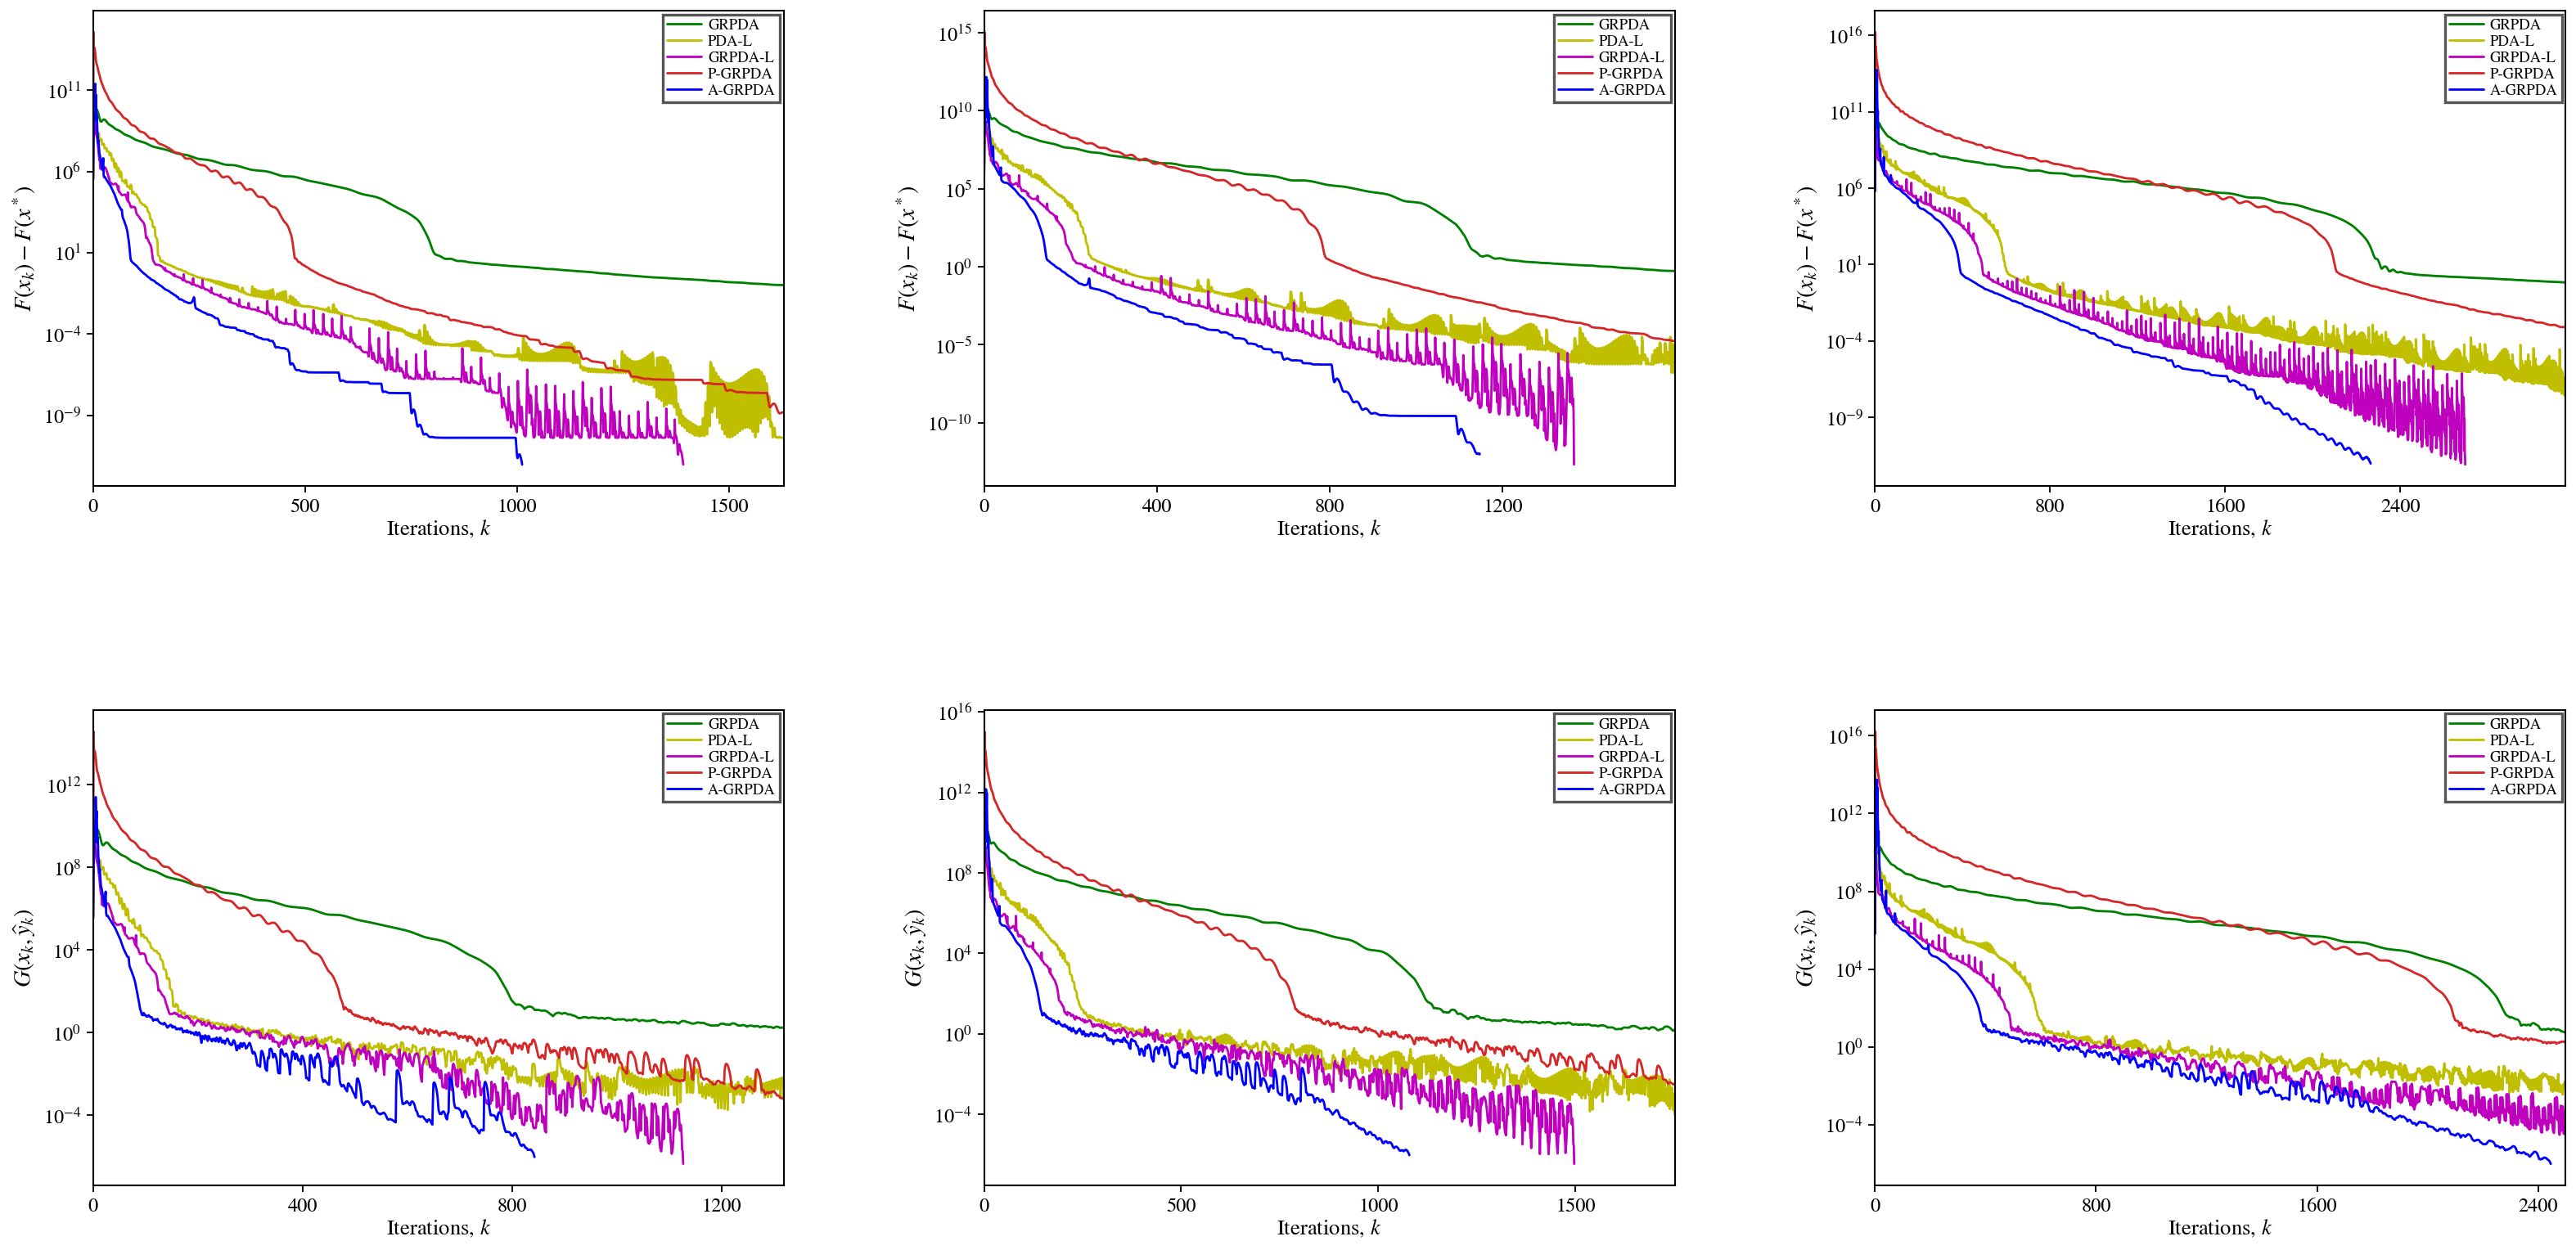

In [8]:
from IPython.display import display, Image
# Reproduce the reference format from unmodified five-algorithm history CSVs.
render(DATA_DIR, mode='focus')  # enlarged horizontal axis for the fast methods
render(DATA_DIR, mode='full')   # complete recorded iteration range
print('Six-panel paper figure:', DATA_DIR/'figure_reference_six_focus.pdf')
display(Image(filename=str(DATA_DIR/'figure_reference_six_focus.png')))

In [9]:
# Strong comparison CONFIGURATION: preserve LASSOEXAMPLE source settings.
from pathlib import Path
import numpy as np
import numpy.linalg as LA
import pandas as pd
import json, contextlib, io, time as strong_clock
from itertools import count
from threadpoolctl import threadpool_limits
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, LogLocator, LogFormatterMathtext
from IPython.display import display

STRONG_PROFILE = 'original_code'     # alternative 'manuscript_text' (different experiment)
STRONG_MAIN_MAX_ITER = 8000          # original comparison
STRONG_MAIN_TOL = 1e-10              # original objective-error tolerance
STRONG_GAP_MAX_ITER = 30000          # pointwise PD gap, separate runs
STRONG_GAP_TOL = 1e-10
STRONG_REF_ITER = 20000              # original two-algorithm reference
STRONG_REFERENCE_MODE = 'source'     # 'source' matches LASSOEXAMPLE; 'sklearn' is alternative
STRONG_RUN_OBJECTIVE = True
STRONG_RUN_GAP = True
STRONG_MU = 0.3                      # original line-search reduction for both baselines
STRONG_MU_SENSITIVITY_VALUES = (0.1, 0.3, 0.7, 0.9)  # common mu for APDA-L and AGRPDA-L
STRONG_MU_TOL = STRONG_MAIN_TOL          # same objective-error tolerance as the main run
STRONG_MU_MAX_ITER = STRONG_MAIN_MAX_ITER  # same iteration budget as the main run
STRONG_SEED, STRONG_SPARSITY = 100, 10
STRONG_OUT = Path.cwd()/'results'/'strong_convex'
STRONG_OUT.mkdir(parents=True, exist_ok=True)

try:
    import importlib
    _pd_strong = importlib.import_module('methods.pd_algorithms')
    _gr_strong = importlib.import_module('methods.gr_pd_algorithms')
    _op_strong = importlib.import_module('opt_operators')
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        'Strong-convex source algorithms were external imports in the uploaded LASSOEXAMPLE. '
        'Place the merged notebook in the original project folder containing methods/pd_algorithms.py, '
        'methods/gr_pd_algorithms.py and opt_operators.py. No strong algorithm has been replaced. '
        f'Original import error: {exc}'
    ) from exc

def _original_method(name):
    for module in (_gr_strong, _pd_strong):
        if hasattr(module,name):
            return getattr(module,name)
    raise AttributeError('Original project code is missing algorithm: '+name)

_original_accel_adaptive = _original_method('pd_adaptive_accelerated_Golden1')
_original_accel_reference = _original_method('pd_accelerated_Golden_linesearch')
_original_pd_reference = _original_method('pd_linesearch_acceler_dual_is_square_norm')

print('Strong algorithms imported from original source modules (not redefined).')


Strong algorithms imported from original source modules (not redefined).


In [10]:
def pd_linesearch_acceler_dual_is_square_norm2_mu_variant(J1, prox_g, prox_f_conj, K, x0, y1, tau, beta, gamma, min_val, numb_iter=100, tol=1e-08, stats=None, *, mu=0.3):
    begin = time()
    values = [J1(x0, y1, min_val)]
    tt = [0]
    steps = []
    theta = 1
    phi = 1.4
    delta = 0.99
    iterates = [values, x0, y1, theta, tau, beta, K.dot(x0)] + [tt, 0]
    if stats is not None:
        stats.setdefault('line_search_trials', 0)
        stats.setdefault('rejected_trials', 0)
        stats.setdefault('outer_iterations', 0)

    def T(values, x_old, y, th_old, tau_old, beta_old, Kx_old, tt, l):
        KTy = K.T.dot(y)
        x = prox_g(x_old - tau_old * KTy, tau_old)
        Kx = K.dot(x)
        KTKx = K.T.dot(Kx)
        beta = beta_old / (1.0 + gamma * beta_old * tau_old)
        sqrt_beta = np.sqrt(beta)
        tau = tau_old * np.sqrt(1.0 + th_old)
        for j in count(0):
            if stats is not None:
                stats['line_search_trials'] += 1
            th = tau / tau_old
            y1 = prox_f_conj(y + tau * beta * Kx, tau * beta)
            if sqrt_beta * tau * LA.norm(K.T.dot(y1) - K.T.dot(y)) <= delta * LA.norm(y1 - y):
                break
            else:
                tau *= mu
                l += 1
                if stats is not None:
                    stats['rejected_trials'] += 1
        values.append(J1(x, y1, min_val))
        tt.append(time() - begin)
        res = [values, x, y1, theta, tau, beta, Kx, tt, l]
        return res
    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats['outer_iterations'] = i + 1
        err = iterates[0][-1]
        end = time()
        if (err <= tol).all():
            print('Iter:', i + 1)
            print('-----Accelerated Golden-Ratio PDA-----')
            print('Time execution:', round(end - begin, 2))
            break
        if (err > tol).all():
            print('Accelerated Golden-Ratio PDA method with  does not terminate after', round(end - begin, 2), 'seconds')
            print('Iter:', i + 1)
    return [iterates[i] for i in [0, 1, -2, -1]]

def pd_accelerated_Golden_linesearch_mu_variant(J, prox_g, prox_f_conj, K, x0, y1, tau, beta, gamma, min_val, numb_iter=100, tol=1e-08, stats=None, *, mu=0.3):
    """ 
    Golden-Ratio PDA with linesearch for problem min_x max_y [
    <Kx,y> + g(x) - f*(y)].    
    beta denotes sigma/tau from a classical primal-dual algorithm.
    where g is gamma-strongly convex
    """
    begin = time()
    theta = 1
    values = [J(x0, y1, min_val)]
    tt = [0]
    steps = []
    phi = 1.4
    rho = 1 / phi + 1 / phi ** 2
    iterates = [values, x0, x0, y1, tau, beta, K.dot(x0)] + [tt, 0]
    sqrt_b = np.sqrt(beta)
    if stats is not None:
        stats.setdefault('line_search_trials', 0)
        stats.setdefault('rejected_trials', 0)
        stats.setdefault('outer_iterations', 0)

    def T(values, z, x_old, y, tau_old, beta_old, Kx_old, tt, l):
        z = ((phi - 1) * x_old + z) / phi
        x = prox_g(z - tau_old * K.T.dot(y), tau_old)
        Kx = K.dot(x)
        w = (phi - rho) / (phi + rho * gamma * tau_old)
        beta = (1 + w * gamma * tau_old) * beta_old
        tau = tau_old * rho
        sqrt_b = np.sqrt(beta)
        for j in count(0):
            if stats is not None:
                stats['line_search_trials'] += 1
            th = tau / tau_old
            y1 = prox_f_conj(y + tau * beta * Kx, tau * beta)
            if sqrt_b * tau * LA.norm(K.T.dot(y1 - y)) <= np.sqrt(phi * th + gamma * tau) * LA.norm(y1 - y):
                break
            else:
                tau *= mu
                l += 1
                if stats is not None:
                    stats['rejected_trials'] += 1
        values.append(J(x, y1, min_val))
        tt.append(time() - begin)
        res = [values, z, x, y1, tau, beta, Kx, tt, l]
        return res
    for i in range(numb_iter):
        iterates = T(*iterates)
        if stats is not None:
            stats['outer_iterations'] = i + 1
        err = iterates[0][-1]
        end = time()
        if (err <= tol).all():
            print('Iter:', i + 1)
            print('-----Accelerated Golden-Ratio Primal-dual method with linesearch-----')
            print('Time execution:', round(end - begin, 2))
            break
    if (err > tol).all():
        print('Accelerated Golden-Ratio Primal-dual method with linesearch does not terminate after', round(end - begin, 2), 'seconds')
        print('Iter:', i + 1)
        print('Number of linesearch:', iterates[-1])
    return [iterates[i] for i in [0, 1, -2, -1]]

In [11]:
# Source-exact strong LASSO cases, with isolated names (never override general cases).
STRONG_ALGORITHM_ORDER = ('APDA-L','AGRPDA-L','A-AGRPDA')

STRONG_CASE_SPECS = {
    'original_code': (
        ('strong_i', 500, 100, 1.0, 0.0),
        ('strong_ii_v01', 500, 100, 0.2, 0.1),
    ),
    'manuscript_text': (
        ('strong_i', 100, 500, 1.0, 0.0),
        ('strong_ii_v02', 100, 500, 0.2, 0.2),
    ),
}
if STRONG_PROFILE not in STRONG_CASE_SPECS:
    raise ValueError('Unexpected STRONG_PROFILE')

class StrongAdjoint:
    def __init__(self,parent): self.parent=parent
    def dot(self,v):
        self.parent.KT_calls+=1
        return self.parent.A.T.dot(v)
class StrongCountedOperator:
    def __init__(self,A):
        self.A=A;self.K_calls=0;self.KT_calls=0;self.T=StrongAdjoint(self)
    def dot(self,v):
        self.K_calls+=1
        return self.A.dot(v)

def _strong_problem(spec):
    name,rows,cols,lam,v=spec
    seed=STRONG_SEED
    rng=np.random.RandomState(seed)
    B=rng.normal(0,1,(rows,cols))
    if v:
        K=np.empty_like(B)
        K[:,0]=B[:,0]/np.sqrt(1-v*v)
        for j in range(1,cols): K[:,j]=v*K[:,j-1]+B[:,j]
    else:
        K=B
    if STRONG_PROFILE=='original_code':
        w=np.random.RandomState(seed).uniform(-10,10,cols)
        noise_std=0.1
    else:
        w=np.random.RandomState(seed).normal(0,1,cols)
        noise_std=np.sqrt(.1)
    w[STRONG_SPARSITY:]=0
    w=np.random.RandomState(seed).permutation(w)
    noise=np.random.RandomState(seed).normal(0,noise_std,rows)
    b=K.dot(w)+noise
    if min(rows,cols)<=150:
        norm_K=float(LA.norm(K,2))
    else:
        norm_K=float(svds(K,k=1,which='LM',return_singular_vectors=False,
                          v0=np.ones(min(K.shape))/np.sqrt(min(K.shape)),tol=1e-11)[0])
    x0=np.zeros(cols);y0=-b.copy()
    dy=(y0+np.random.RandomState(seed).random_sample(rows)*1e-12)-y0
    denom=float(LA.norm(K.T.dot(dy)))
    if denom<=0: raise ValueError('Degenerate initial direction')
    zeta=float(LA.norm(dy)/denom)
    return dict(name=name,A=K,b=b,lam=lam,v=v,rows=rows,cols=cols,
                L=norm_K,zeta=zeta,x0=x0,y0=y0)

def _strong_prox_primal(x,t,lam):
    # Standard LASSO prox; matches opt_operators.prox_norm_1(x,lam*t).
    return np.sign(x)*np.maximum(np.abs(x)-lam*t,0.)

def _strong_objective(case,x):
    r=case['A'].dot(x)-case['b']
    return .5*float(r.dot(r))+case['lam']*LA.norm(x,1)

def _strong_source_reference(case):
    # The exact LASSOEXAMPLE reference construction, using its ORIGINAL modules.
    K,b,lam,x0,y0,zeta=case['A'],case['b'],case['lam'],case['x0'],case['y0'],case['zeta']
    def J(x,y,ref): return abs(_strong_objective(case,x)-ref)
    def J1(y,x,ref): return abs(_strong_objective(case,x)-ref)
    def pg(x,t): return _strong_prox_primal(x,t,lam)
    def pf(y,t): return (y-t*b)/(1.+t)
    with contextlib.redirect_stdout(io.StringIO()):
        trial1=_original_accel_reference(J1,pf,pg,-K.T,y0,x0,zeta,1,.01,0,
                                          numb_iter=STRONG_REF_ITER,tol=0)
        trial2=_original_pd_reference(J,pg,b,K,x0,y0,zeta/np.sqrt(5),1,.01,0,
                                      numb_iter=STRONG_REF_ITER)
    return float(min(np.min(trial1[0]),np.min(trial2[1])))

def _strong_ref(case):
    if STRONG_REFERENCE_MODE=='source':
        return _strong_source_reference(case), 'original_source_two_algorithm'
    if STRONG_REFERENCE_MODE=='sklearn':
        from sklearn.linear_model import Lasso
        K,b,lam=case['A'],case['b'],case['lam']
        mdl=Lasso(alpha=lam/K.shape[0],fit_intercept=False,
                  max_iter=100000,tol=1e-13,selection='cyclic')
        mdl.fit(K,b)
        return _strong_objective(case,mdl.coef_), 'sklearn_lasso'
    raise ValueError('Unknown STRONG_REFERENCE_MODE')

def _strong_parameters(case):
    L,zeta=case['L'],case['zeta']
    tau_apda=zeta/np.sqrt(5.)
    tau_ag=zeta*np.sqrt(1.5/0.45)
    tau_a=np.sqrt(.99*1.5/(.1*L**2))
    gamma=.01
    omega=(1.5-1)/(1.5+gamma*tau_a)
    beta1=(1+omega*gamma*tau_a)*.1
    return {
       'APDA-L':dict(tau0=tau_apda,beta0=.5,gamma=1.,mu=STRONG_MU,
                     phi=1.4,delta=.99),
       'AGRPDA-L':dict(tau0=tau_ag,beta0=.45,gamma=.01,mu=STRONG_MU,
                       phi=1.4),
       'A-AGRPDA':dict(tau0=tau_a,tau1=tau_a,beta0=.1,beta1=beta1,
                       gamma=.01,psi=1.5,sigma=.99,paper_rule=False,
                       xi='not applicable',eta='not applicable'),
    }

def _strong_objective_and_gap_metrics(case,ref,metric_name):
    A,b,lam=case['A'],case['b'],case['lam']
    measurements=[]
    def metric_swapped(y,x,_):
        if metric_name=='objective':
            val=abs(_strong_objective(case,x)-ref)
        else:
            # Feasible-dual, last-iterate, NOT ergodic gap.
            Aty=A.T.dot(y)
            scale=max(1.,float(np.max(np.abs(Aty)))/lam)
            yhat=y/scale;atyhat=Aty/scale
            residual=A.dot(x)-b
            # Same stable identity as in the original source notebook.
            discrepancy=residual-yhat
            slack=np.maximum(lam+np.sign(x)*atyhat,0.)
            val=.5*float(discrepancy.dot(discrepancy))+float(np.sum(np.abs(x)*slack))
        if not np.isfinite(val):
            raise FloatingPointError('Nonfinite strong-convex metric')
        measurements.append(float(val))
        return np.asarray(val)
    return metric_swapped,measurements

def _strong_run_one(case,method,ref,metric='objective',max_iter=None,tol=None,mu=None):
    pars=_strong_parameters(case)[method]
    run_mu = STRONG_MU if mu is None else float(mu)
    if method in ('APDA-L','AGRPDA-L') and not (0.0 < run_mu < 1.0):
        raise ValueError('Line-search mu must lie in (0,1).')
    if max_iter is None: max_iter=(STRONG_MAIN_MAX_ITER if metric=='objective' else STRONG_GAP_MAX_ITER)
    if tol is None: tol=(STRONG_MAIN_TOL if metric=='objective' else STRONG_GAP_TOL)
    op=StrongCountedOperator(-case['A'].T)
    prox_ctr=[0,0]
    b,lam=case['b'],case['lam']
    def px(x,t):
        prox_ctr[1]+=1
        return _strong_prox_primal(x,t,lam)
    def py(y,t):
        prox_ctr[0]+=1
        return (y-t*b)/(1+t)
    callback,measurements=_strong_objective_and_gap_metrics(case,ref,metric)
    stats={}
    tic=strong_clock.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):
        if method=='APDA-L':
            result=pd_linesearch_acceler_dual_is_square_norm2_mu_variant(
                callback,py,px,op,case['y0'],case['x0'],pars['tau0'],
                pars['beta0'],pars['gamma'],ref,numb_iter=max_iter,tol=tol,
                stats=stats,mu=run_mu)
        elif method=='AGRPDA-L':
            result=pd_accelerated_Golden_linesearch_mu_variant(
                callback,py,px,op,case['y0'],case['x0'],pars['tau0'],
                pars['beta0'],pars['gamma'],ref,numb_iter=max_iter,tol=tol,
                stats=stats,mu=run_mu)
        else:
            result=_original_accel_adaptive(
                callback,py,px,op,case['y0'],case['x0'],[pars['tau0'],pars['tau1']],
                pars['beta1'],pars['gamma'],ref,numb_iter=max_iter,tol=tol,
                psi=pars['psi'],sigma=pars['sigma'],paper_rule=False)
    elapsed=strong_clock.perf_counter()-tic
    values=np.asarray(result[0],dtype=float).reshape(-1)
    if not len(values) or not np.all(np.isfinite(values)):
        raise FloatingPointError(f'{case["name"]} {method}: non-finite run')
    if len(values)!=len(measurements):
        raise AssertionError('Metric history length differs from original returned history')
    it=len(values)-1
    hits=np.flatnonzero(values<=tol)
    reached=bool(len(hits))
    info=dict(Family='strong',Profile=STRONG_PROFILE,Case=case['name'],
       Algorithm=method,Metric='F_error' if metric=='objective' else 'PD_gap',
       Iter=it,HitIter=int(hits[0]) if reached else np.nan,
       Reached=reached,CPU_wall_s=elapsed,
       Avg_ms_per_iter=elapsed*1000/it if it>0 else np.nan,
       Final_error=float(values[-1]),Tolerance=tol,
       MaxIter=max_iter,F_reference=ref,
       K_calls=op.K_calls,KT_calls=op.KT_calls,
       Operator=op.K_calls+op.KT_calls,
       Prox_primal=prox_ctr[1],Prox_dual=prox_ctr[0],
       Prox=prox_ctr[0]+prox_ctr[1],
       LS=int(stats.get('line_search_trials',0)),
       Rejected_LS=int(stats.get('rejected_trials',0)),
       Diagnostic_K=it+1 if metric=='gap' else it+1,
       Diagnostic_KT=it+1 if metric=='gap' else 0,
       Rows=case['rows'],Cols=case['cols'],lambda_reg=case['lam'],v=case['v'],
       tau0=pars['tau0'],beta0=pars['beta0'],gamma=pars['gamma'],
       mu=(run_mu if method in ('APDA-L','AGRPDA-L') else np.nan),
       psi=pars.get('psi',np.nan),sigma=pars.get('sigma',np.nan),
       beta1=pars.get('beta1',np.nan))
    for col in ('Operator','Prox','LS'):
        info[col+'_per_iter']=info[col]/it if it else np.nan
    return info,pd.DataFrame({'Iter':np.arange(len(values)),
                               'F_error' if metric=='objective' else 'PD_gap':values,
                               'Native_time_s':np.asarray(result[2],dtype=float)[:len(values)]})

def _strong_plot(all_curves,metric,mode,output_dir):
    names=[('strong_i','(i)'),
           ('strong_ii_v01' if STRONG_PROFILE=='original_code' else 'strong_ii_v02',
            '(ii)')]
    palette={'APDA-L':'#9932CC','AGRPDA-L':'#00BFBF','A-AGRPDA':'#0000FF'}
    fig,axes=plt.subplots(1,2,figsize=(9.1,3.25))
    fig.subplots_adjust(left=.09,right=.985,top=.95,bottom=.21,wspace=.34)
    for ax,(case_id,label) in zip(axes,names):
        series=all_curves.get(case_id,{})
        if not series:
            ax.set_visible(False);continue
        terminal=max(int(hist['Iter'].iloc[-1]) for hist in series.values())
        eps=STRONG_MAIN_TOL if metric=='objective' else STRONG_GAP_TOL
        hits=sorted(int(np.flatnonzero(hist['val'].to_numpy()<=eps)[0])
                    for hist in series.values() if (hist['val']<=eps).any())
        xcap=terminal if mode=='full' else max(50,int(np.ceil(1.15*hits[min(1,len(hits)-1)]))) if hits else min(terminal,500)
        for method in STRONG_ALGORITHM_ORDER:
            if method not in series:
                continue
            hist=series[method]
            m=hist['Iter']<=xcap
            x=hist.loc[m,'Iter'].to_numpy()
            y=hist.loc[m,'val'].to_numpy()
            ax.semilogy(x,np.where(y>0,y,np.nan),color=palette[method],
                        linestyle='-',linewidth=.9,label=method)
        ax.set_xlim(0,max(1,xcap))
        ax.set_xlabel(r'Iterations, $k$')
        ax.set_ylabel(r'$|F(x_k)-F_{\mathrm{ref}}|$' if metric=='objective'
                      else r'$G(x_k,\widehat{y}_k)$')
        ax.legend(loc='upper right',fontsize=7,frameon=True,fancybox=False,
                  framealpha=1,edgecolor='#555555')
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5,integer=True))
        ax.grid(False)
        for spine in ax.spines.values():spine.set_linewidth(.65)
    for ext in ('png','pdf'):
        fig.savefig(output_dir/f'strong_{metric}_{mode}.{ext}',dpi=220,
                    bbox_inches='tight',pad_inches=.05)
    plt.close(fig)

def run_strong_comparisons():
    STRONG_OUT.mkdir(parents=True,exist_ok=True)
    all_rows=[];all_params=[]
    plots={'objective':{},'gap':{}}
    for spec in STRONG_CASE_SPECS[STRONG_PROFILE]:
        case=_strong_problem(spec)
        ref,ref_method=_strong_ref(case)
        params=_strong_parameters(case)
        for name,setting in params.items():
            all_params.append(dict(Family='strong',Profile=STRONG_PROFILE,Case=case['name'],
                                   Algorithm=name,Reference_method=ref_method,
                                   **setting,Rows=case['rows'],Cols=case['cols'],
                                   v=case['v'],lambda_reg=case['lam'],L=case['L'],zeta=case['zeta']))
        case_dir=STRONG_OUT/case['name'];case_dir.mkdir(exist_ok=True)
        metric_runs=(('objective',STRONG_MAIN_MAX_ITER,STRONG_MAIN_TOL) if STRONG_RUN_OBJECTIVE else None,
                     ('gap',STRONG_GAP_MAX_ITER,STRONG_GAP_TOL) if STRONG_RUN_GAP else None)
        for spec2 in filter(None,metric_runs):
            metric,max_iter,tol=spec2
            for method in STRONG_ALGORITHM_ORDER:
                row,history=_strong_run_one(case,method,ref,metric,max_iter,tol)
                row['Reference_method']=ref_method
                all_rows.append(row)
                label='F_error' if metric=='objective' else 'PD_gap'
                history.to_csv(case_dir/f'{metric}_{method}_history.csv',index=False)
                plots[metric].setdefault(case['name'],{})[method]=history.rename(columns={label:'val'})
                print(f'{case["name"]:15s} {metric:10s} {method:9s} '
                      f'Iter={row["Iter"]:6d} reached={row["Reached"]} '
                      f'CPU={row["CPU_wall_s"]:.4f}s '
                      f'Operator={row["Operator"]:7d} Prox={row["Prox"]:7d} '
                      f'LS={row["LS"]:6d} final={row["Final_error"]:.3e}')
        pd.DataFrame([r for r in all_rows if r['Case']==case['name']]).to_csv(
            case_dir/'strong_costs.csv',index=False)
    _strong_rank={name:i for i,name in enumerate(STRONG_ALGORITHM_ORDER)}
    result=pd.DataFrame(all_rows)
    if not result.empty:
        result['_algorithm_rank']=result['Algorithm'].map(_strong_rank)
        result=result.sort_values(['Case','Metric','_algorithm_rank'],kind='stable').drop(columns='_algorithm_rank')
    result.to_csv(STRONG_OUT/'strong_all_metrics_and_costs.csv',index=False)
    params_df=pd.DataFrame(all_params)
    if not params_df.empty:
        params_df['_algorithm_rank']=params_df['Algorithm'].map(_strong_rank)
        params_df=params_df.sort_values(['Case','_algorithm_rank'],kind='stable').drop(columns='_algorithm_rank')
    params_df.to_csv(STRONG_OUT/'strong_algorithm_parameter_settings.csv',index=False)
    for metric,cases in plots.items():
        if cases:
            for mode in ('focus','full'):
                _strong_plot(cases,metric,mode,STRONG_OUT)
    return result,params_df


# ---------------------------------------------------------------------------
# Separate strong-convex line-search mu sensitivity.
# APDA-L and AGRPDA-L are rerun for each mu; A-AGRPDA is a fixed reference.
# ---------------------------------------------------------------------------
STRONG_MU_LINESEARCH_METHODS = ('APDA-L', 'AGRPDA-L')
STRONG_MU_BASELINE_METHOD = 'A-AGRPDA'
STRONG_MU_ALGORITHMS = ('APDA-L', 'AGRPDA-L', 'A-AGRPDA')
# Kept as the complete display order for the final experiment manifest.
STRONG_MU_METHODS = STRONG_MU_ALGORITHMS

STRONG_MU_PALETTE = {
    'APDA-L': '#9932CC',
    'AGRPDA-L': '#00BFBF',
    'A-AGRPDA': '#0000FF',
}


def _strong_mu_plot_three_algorithms(case_id, case_label, curves_by_mu,
                                     mode, output_dir):
    """Save one reference-style three-curve figure for each mu value.

    Each single-panel figure compares APDA-L, AGRPDA-L and A-AGRPDA
    using the same objective-error history. A-AGRPDA is listed last
    in the legend. A 2x2 overview is also saved.
    """
    plot_order = ('APDA-L', 'AGRPDA-L', 'A-AGRPDA')

    def _focus_limit(panel):
        hit_iters = []
        terminal_iters = []
        for method in plot_order:
            if method not in panel:
                continue
            hist = panel[method]
            it = hist['Iter'].to_numpy(dtype=int)
            val = hist['F_error'].to_numpy(dtype=float)
            if len(it):
                terminal_iters.append(int(it[-1]))
            hit = np.flatnonzero(np.isfinite(val) & (val <= STRONG_MU_TOL))
            if len(hit):
                hit_iters.append(int(it[int(hit[0])]))
        terminal = max(terminal_iters, default=1)
        if mode == 'full':
            return max(1, terminal)
        if hit_iters:
            return max(1, min(terminal, int(np.ceil(1.12 * max(hit_iters)))))
        return max(1, min(terminal, 800))

    def _draw_panel(ax, panel):
        available = [name for name in plot_order if name in panel]
        if not available:
            ax.text(.5, .5, 'No recorded history', ha='center', va='center',
                    transform=ax.transAxes)
            return

        xcap = _focus_limit(panel)
        for method in plot_order:
            if method not in panel:
                continue
            hist = panel[method]
            mask = hist['Iter'].to_numpy(dtype=int) <= xcap
            x = hist.loc[mask, 'Iter'].to_numpy(dtype=int)
            y = hist.loc[mask, 'F_error'].to_numpy(dtype=float)
            y = np.where(np.isfinite(y) & (y > 0), y, np.nan)
            ax.semilogy(
                x, y,
                color=STRONG_MU_PALETTE[method],
                linestyle='-',
                linewidth=1.0,
                label=method
            )

        ax.set_xlim(0, xcap)
        ax.set_xlabel(r'Iterations, $k$')
        ax.set_ylabel(r'$F(x_k)-F(x^*)$')
        ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
        ax.legend(
            loc='best', fontsize=8, frameon=True, fancybox=False,
            framealpha=1, edgecolor='#555555'
        )
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_linewidth(.7)
        ax.tick_params(axis='both', labelsize=8)

    # First save a separate, full-size, three-curve plot for every mu.
    for mu_value in STRONG_MU_SENSITIVITY_VALUES:
        panel = curves_by_mu.get(float(mu_value), {})
        safe_mu = str(float(mu_value)).replace('.', 'p')
        fig, ax = plt.subplots(figsize=(5.8, 3.5))
        fig.subplots_adjust(left=.14, right=.98, top=.98, bottom=.17)
        _draw_panel(ax, panel)
        for ext in ('png', 'pdf'):
            fig.savefig(
                output_dir / f'{case_id}_mu_{safe_mu}_three_algorithm_{mode}.{ext}',
                dpi=300, bbox_inches='tight', pad_inches=.05
            )
        plt.close(fig)

    # Also save a compact 2x2 overview of the four mu settings.
    fig, axes = plt.subplots(2, 2, figsize=(9.2, 6.2))
    fig.subplots_adjust(left=.09, right=.985, top=.985, bottom=.09,
                        wspace=.30, hspace=.38)
    for ax, mu_value in zip(axes.flat, STRONG_MU_SENSITIVITY_VALUES):
        panel = curves_by_mu.get(float(mu_value), {})
        _draw_panel(ax, panel)
    for ext in ('png', 'pdf'):
        fig.savefig(
            output_dir / f'{case_id}_mu_three_algorithm_{mode}_overview.{ext}',
            dpi=260, bbox_inches='tight', pad_inches=.06
        )
    plt.close(fig)

def _strong_mu_get_fixed_baseline(case, ref, ref_method, case_dir):
    """Get one genuine A-AGRPDA run per case, reusing the matching main run if possible."""
    pars = _strong_parameters(case)[STRONG_MU_BASELINE_METHOD]
    main_history_path = (
        STRONG_OUT / case['name'] / 'objective_A-AGRPDA_history.csv'
    )
    main_summary_path = STRONG_OUT / 'strong_all_metrics_and_costs.csv'

    baseline = None
    baseline_history = None
    reused_from_main = False

    # The main comparison is executed before this cell. Reuse its A-AGRPDA
    # objective run only when the case, reference, tolerance, budget and
    # algorithm initialization all match exactly.
    if main_history_path.is_file() and main_summary_path.is_file():
        main_table = pd.read_csv(main_summary_path)
        mask = (
            (main_table['Case'] == case['name']) &
            (main_table['Metric'] == 'F_error') &
            (main_table['Algorithm'] == STRONG_MU_BASELINE_METHOD) &
            (main_table['MaxIter'] == STRONG_MU_MAX_ITER) &
            np.isclose(main_table['Tolerance'].to_numpy(dtype=float), STRONG_MU_TOL) &
            np.isclose(main_table['F_reference'].to_numpy(dtype=float), ref,
                       rtol=1e-12, atol=1e-10) &
            (main_table['Rows'] == case['rows']) &
            (main_table['Cols'] == case['cols'])
        )
        if 'Profile' in main_table.columns:
            mask &= (main_table['Profile'] == STRONG_PROFILE)
        candidates = main_table.loc[mask]
        if len(candidates) == 1:
            candidate = candidates.iloc[0].to_dict()
            candidate_history = pd.read_csv(main_history_path)
            same_initialization = (
                np.isclose(float(candidate['beta0']), pars['beta0']) and
                np.isclose(float(candidate['tau0']), pars['tau0']) and
                np.isclose(float(candidate['gamma']), pars['gamma'])
            )
            valid_history = (
                'F_error' in candidate_history.columns and
                len(candidate_history) == int(candidate['Iter']) + 1 and
                np.all(np.isfinite(candidate_history['F_error'].to_numpy(dtype=float)))
            )
            if same_initialization and valid_history:
                baseline = candidate
                baseline_history = candidate_history
                reused_from_main = True

    # If there is no exact matching main-comparison run, execute A-AGRPDA once.
    if baseline is None:
        baseline, baseline_history = _strong_run_one(
            case, STRONG_MU_BASELINE_METHOD, ref,
            metric='objective', max_iter=STRONG_MU_MAX_ITER,
            tol=STRONG_MU_TOL
        )

    baseline = dict(baseline)
    baseline.update(
        Experiment='strong_mu_sensitivity',
        Metric='F_error',
        Mu=np.nan,                 # A-AGRPDA has no line-search mu.
        mu_applies=False,
        Is_reused_reference=True,  # reused across all four mu panels.
        Was_reused_from_main_comparison=bool(reused_from_main),
        Reference_method=ref_method,
    )
    baseline['Algorithm'] = STRONG_MU_BASELINE_METHOD
    baseline['beta0'] = pars['beta0']
    baseline_history.to_csv(
        case_dir / 'A-AGRPDA_fixed_reference_history.csv', index=False
    )
    return baseline, baseline_history, reused_from_main


def run_strong_mu_sensitivity():
    """Compare APDA-L, AGRPDA-L and fixed A-AGRPDA for each requested mu.

    Only APDA-L and AGRPDA-L are rerun when mu changes. A-AGRPDA has no
    line-search mu and is run once per case, then repeated as a labelled
    reference row in each mu-specific comparison table. This experiment
    uses the objective-error criterion only; the main PD-gap experiment is
    left untouched.
    """
    if not STRONG_RUN_OBJECTIVE:
        raise RuntimeError(
            'Set STRONG_RUN_OBJECTIVE=True before running the mu sensitivity; '
            'the mu experiment uses the same objective-error stopping rule.'
        )

    out_root = STRONG_OUT / 'mu_sensitivity'
    out_root.mkdir(parents=True, exist_ok=True)

    comparison_rows = []       # Three rows per (case, mu), including fixed baseline.
    line_search_rows = []      # Actual APDA-L / AGRPDA-L runs only.
    baseline_rows = []         # One genuine A-AGRPDA run per case.
    parameter_rows = []
    all_case_curves = {}

    for case_spec in STRONG_CASE_SPECS[STRONG_PROFILE]:
        case = _strong_problem(case_spec)
        case_id = case['name']
        ref, ref_method = _strong_ref(case)
        case_dir = out_root / case_id
        case_dir.mkdir(parents=True, exist_ok=True)
        pars_all = _strong_parameters(case)

        baseline, baseline_history, reused_from_main = _strong_mu_get_fixed_baseline(
            case, ref, ref_method, case_dir
        )
        baseline_rows.append(baseline)
        baseline_source = (
            'main_comparison' if reused_from_main else 'single_mu_sensitivity_run'
        )

        # Record A-AGRPDA's true parameter setting once, not once per mu.
        base_pars = pars_all[STRONG_MU_BASELINE_METHOD].copy()
        parameter_rows.append(dict(
            Family='strong', Experiment='strong_mu_sensitivity',
            Profile=STRONG_PROFILE, Case=case_id,
            Algorithm=STRONG_MU_BASELINE_METHOD, Mu=np.nan,
            mu_applies=False, Is_reused_reference=True,
            Was_reused_from_main_comparison=reused_from_main,
            **base_pars, Rows=case['rows'], Cols=case['cols'],
            v=case['v'], lambda_reg=case['lam'], L=case['L'], zeta=case['zeta']
        ))

        case_curves = {}
        case_comparison_rows = []

        for mu_value in STRONG_MU_SENSITIVITY_VALUES:
            mu_value = float(mu_value)
            panel_curves = {STRONG_MU_BASELINE_METHOD: baseline_history}
            current_rows = []

            # Only these two algorithms receive and respond to the varied mu.
            for method in STRONG_MU_LINESEARCH_METHODS:
                row, history = _strong_run_one(
                    case, method, ref, metric='objective',
                    max_iter=STRONG_MU_MAX_ITER, tol=STRONG_MU_TOL,
                    mu=mu_value
                )
                row.update(
                    Experiment='strong_mu_sensitivity',
                    Mu=mu_value,
                    mu_applies=True,
                    Is_reused_reference=False,
                    Was_reused_from_main_comparison=False,
                    Reference_method=ref_method,
                )
                if not np.isclose(float(row['beta0']), pars_all[method]['beta0']):
                    raise AssertionError(f'{method}: beta0 changed during mu sensitivity.')

                safe_mu = str(mu_value).replace('.', 'p')
                history.to_csv(
                    case_dir / f'objective_{method}_mu_{safe_mu}_history.csv',
                    index=False
                )
                panel_curves[method] = history
                current_rows.append(row)
                line_search_rows.append(row)

                method_pars = pars_all[method].copy()
                method_pars.pop('mu', None)  # the varied value is stored in Mu below.
                parameter_rows.append(dict(
                    Family='strong', Experiment='strong_mu_sensitivity',
                    Profile=STRONG_PROFILE, Case=case_id,
                    Algorithm=method, Mu=mu_value,
                    mu_applies=True, Is_reused_reference=False,
                    Was_reused_from_main_comparison=False,
                    **method_pars, Rows=case['rows'], Cols=case['cols'],
                    v=case['v'], lambda_reg=case['lam'], L=case['L'], zeta=case['zeta']
                ))

                print(
                    f'{case_id:15s} {method:9s} mu={mu_value:.1f} '
                    f'Iter={row["Iter"]:6d} reached={row["Reached"]} '
                    f'CPU={row["CPU_wall_s"]:.4f}s '
                    f'Operator={row["Operator"]:7d} Prox={row["Prox"]:7d} '
                    f'LS={row["LS"]:6d} final={row["Final_error"]:.3e}'
                )

            # Add the same A-AGRPDA result to this mu panel. Its actual run,
            # time and counts are unchanged; Mu labels the comparison panel only.
            baseline_at_mu = dict(baseline)
            baseline_at_mu.update(
                Mu=mu_value,
                mu_applies=False,
                Is_reused_reference=True,
                Was_reused_from_main_comparison=bool(reused_from_main),
                Baseline_source=baseline_source,
            )
            for row in current_rows:
                row['Baseline_source'] = baseline_source
            current_rows.append(baseline_at_mu)

            # Explicit, stable algorithm order in every comparison table.
            rank = {name: i for i, name in enumerate(STRONG_MU_ALGORITHMS)}
            current_rows.sort(key=lambda item: rank[item['Algorithm']])
            comparison_rows.extend(current_rows)
            case_comparison_rows.extend(current_rows)
            case_curves[mu_value] = panel_curves

            mu_table = pd.DataFrame(current_rows)
            mu_table.to_csv(
                case_dir / f'mu_{safe_mu}_three_algorithm_comparison.csv',
                index=False
            )

        # Per-case table: four mu values, three algorithms per value.
        case_frame = pd.DataFrame(case_comparison_rows)
        case_frame.to_csv(
            case_dir / 'strong_mu_three_algorithm_comparison.csv', index=False
        )
        case_frame.to_csv(
            case_dir / 'strong_mu_sensitivity_costs.csv', index=False
        )
        all_case_curves[case_id] = case_curves

        case_label = '(i)' if case_id == 'strong_i' else '(ii)'
        for mode in ('focus', 'full'):
            _strong_mu_plot_three_algorithms(
                case_id, case_label, case_curves, mode, case_dir
            )

        print(
            f'\n{case_id}: A-AGRPDA was computed once and reused in all '
            f'{len(STRONG_MU_SENSITIVITY_VALUES)} mu comparisons '
            f'(source: {baseline_source}).'
        )
        display(case_frame[[
            'Case', 'Mu', 'Algorithm', 'Iter', 'HitIter', 'Reached',
            'CPU_wall_s', 'Avg_ms_per_iter', 'Operator', 'Prox', 'LS',
            'Rejected_LS', 'Final_error', 'mu_applies',
            'Is_reused_reference', 'Was_reused_from_main_comparison'
        ]].round(6))

    result = pd.DataFrame(comparison_rows)
    if not result.empty:
        algorithm_rank = {name: i for i, name in enumerate(STRONG_MU_ALGORITHMS)}
        result['_algorithm_rank'] = result['Algorithm'].map(algorithm_rank)
        result = result.sort_values(
            ['Case', 'Mu', '_algorithm_rank'], kind='stable'
        ).drop(columns='_algorithm_rank').reset_index(drop=True)
    result.to_csv(out_root / 'strong_mu_sensitivity_all_metrics.csv', index=False)
    result.to_csv(out_root / 'strong_mu_sensitivity_all_algorithms.csv', index=False)

    line_search_result = pd.DataFrame(line_search_rows)
    if not line_search_result.empty:
        line_search_result = line_search_result.sort_values(
            ['Case', 'Mu', 'Algorithm'], kind='stable'
        ).reset_index(drop=True)
    line_search_result.to_csv(
        out_root / 'strong_mu_sensitivity_line_search_runs.csv', index=False
    )

    baseline_result = pd.DataFrame(baseline_rows)
    if not baseline_result.empty:
        baseline_result = baseline_result.sort_values(
            ['Case'], kind='stable'
        ).reset_index(drop=True)
    baseline_result.to_csv(
        out_root / 'strong_mu_sensitivity_baseline_once_per_case.csv', index=False
    )

    parameter_result = pd.DataFrame(parameter_rows)
    if not parameter_result.empty:
        parameter_result = parameter_result.sort_values(
            ['Case', 'Algorithm', 'Mu'], kind='stable', na_position='first'
        ).reset_index(drop=True)
    parameter_result.to_csv(
        out_root / 'strong_mu_sensitivity_parameter_settings.csv', index=False
    )

    print('\nSaved three-algorithm mu-sensitivity results to:', out_root.resolve())
    print('  - strong_mu_sensitivity_all_metrics.csv')
    print('  - strong_mu_sensitivity_line_search_runs.csv')
    print('  - strong_mu_sensitivity_baseline_once_per_case.csv')
    print('  - strong_mu_sensitivity_parameter_settings.csv')
    print('  - per-case 2x2 figures: *_mu_three_algorithm_focus/full.png and .pdf')
    return result, parameter_result, all_case_curves


In [12]:
strong_results, strong_parameter_settings = run_strong_comparisons()
from IPython.display import display
print('\nSTRONG CONVEX: OBJECTIVE ERROR (first hit + actual costs)')
cols = ['Case','Algorithm','Iter','HitIter','Reached','CPU_wall_s','Avg_ms_per_iter',
        'Operator','Prox','LS','Operator_per_iter','Prox_per_iter',
        'LS_per_iter','Final_error']
display(strong_results.loc[strong_results.Metric=='F_error',cols])
print('\nSTRONG CONVEX: POINTWISE PD GAP (separate runs)')
display(strong_results.loc[strong_results.Metric=='PD_gap',cols])
print('\nACTUAL STRONG PARAMETER SETTINGS (also saved as CSV):')
display(strong_parameter_settings)


strong_i        objective  APDA-L    Iter=   465 reached=True CPU=0.0631s Operator=   2592 Prox=   1063 LS=   598 final=6.592e-11
strong_i        objective  AGRPDA-L  Iter=   353 reached=True CPU=0.0405s Operator=   1120 Prox=    766 LS=   413 final=2.522e-11
strong_i        objective  A-AGRPDA  Iter=   161 reached=True CPU=0.0172s Operator=    484 Prox=    322 LS=     0 final=3.882e-11
strong_i        gap        APDA-L    Iter=   680 reached=True CPU=0.1085s Operator=   3791 Prox=   1555 LS=   875 final=8.188e-11
strong_i        gap        AGRPDA-L  Iter=   697 reached=True CPU=0.0947s Operator=   2211 Prox=   1513 LS=   816 final=9.535e-11
strong_i        gap        A-AGRPDA  Iter=   324 reached=True CPU=0.0421s Operator=    973 Prox=    648 LS=     0 final=9.666e-11
strong_ii_v01   objective  APDA-L    Iter=   522 reached=True CPU=0.0753s Operator=   2911 Prox=   1194 LS=   672 final=9.632e-11
strong_ii_v01   objective  AGRPDA-L  Iter=   217 reached=True CPU=0.0237s Operator=    689

,Case,Algorithm,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Operator_per_iter,Prox_per_iter,LS_per_iter,Final_error
0,strong_i,APDA-L,465,465,True,0.063149,0.135803,2592,1063,598,5.574194,2.286022,1.286022,6.591705e-11
1,strong_i,AGRPDA-L,353,353,True,0.040458,0.114610,1120,766,413,3.172805,2.169972,1.169972,2.522427e-11
2,strong_i,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,3.006211,2.000000,0.000000,3.882406e-11
6,strong_ii_v01,APDA-L,522,522,True,0.075271,0.144197,2911,1194,672,5.576628,2.287356,1.287356,9.631762e-11
7,strong_ii_v01,AGRPDA-L,217,217,True,0.023735,0.109380,689,471,254,3.175115,2.170507,1.170507,6.669509e-11
8,strong_ii_v01,A-AGRPDA,169,169,True,0.021829,0.129169,508,338,0,3.005917,2.000000,0.000000,9.719514e-11



STRONG CONVEX: POINTWISE PD GAP (separate runs)


,Case,Algorithm,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Operator_per_iter,Prox_per_iter,LS_per_iter,Final_error
3,strong_i,APDA-L,680,680,True,0.108536,0.159611,3791,1555,875,5.575000,2.286765,1.286765,8.188361e-11
4,strong_i,AGRPDA-L,697,697,True,0.094744,0.135931,2211,1513,816,3.172166,2.170732,1.170732,9.535202e-11
5,strong_i,A-AGRPDA,324,324,True,0.042124,0.130012,973,648,0,3.003086,2.000000,0.000000,9.665711e-11
9,strong_ii_v01,APDA-L,774,774,True,0.136809,0.176756,4315,1770,996,5.574935,2.286822,1.286822,8.556090e-11
10,strong_ii_v01,AGRPDA-L,495,495,True,0.070248,0.141915,1571,1075,580,3.173737,2.171717,1.171717,9.846947e-11
11,strong_ii_v01,A-AGRPDA,326,326,True,0.043721,0.134114,979,652,0,3.003067,2.000000,0.000000,9.504693e-11



ACTUAL STRONG PARAMETER SETTINGS (also saved as CSV):


,Family,Profile,Case,Algorithm,Reference_method,tau0,beta0,gamma,mu,phi,...,lambda_reg,L,zeta,tau1,beta1,psi,sigma,paper_rule,xi,eta
0,strong,original_code,strong_i,APDA-L,original_source_two_algorithm,0.048837,0.50,1.00,0.3,1.4,...,1.0,32.254621,0.109202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,strong,original_code,strong_i,AGRPDA-L,original_source_two_algorithm,0.199375,0.45,0.01,0.3,1.4,...,1.0,32.254621,0.109202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,strong,original_code,strong_i,A-AGRPDA,original_source_two_algorithm,0.119473,0.10,0.01,NaN,NaN,...,1.0,32.254621,0.109202,0.119473,0.100040,1.5,0.99,False,not applicable,not applicable
3,strong,original_code,strong_ii_v01,APDA-L,original_source_two_algorithm,0.048448,0.50,1.00,0.3,1.4,...,0.2,33.288023,0.108333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,strong,original_code,strong_ii_v01,AGRPDA-L,original_source_two_algorithm,0.197787,0.45,0.01,0.3,1.4,...,0.2,33.288023,0.108333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,strong,original_code,strong_ii_v01,A-AGRPDA,original_source_two_algorithm,0.115764,0.10,0.01,NaN,NaN,...,0.2,33.288023,0.108333,0.115764,0.100039,1.5,0.99,False,not applicable,not applicable


strong_i        APDA-L    mu=0.1 Iter=   772 reached=True CPU=0.1130s Operator=   4093 Prox=   1660 LS=   888 final=8.549e-11
strong_i        AGRPDA-L  mu=0.1 Iter=   437 reached=True CPU=0.0451s Operator=   1351 Prox=    913 LS=   476 final=9.354e-11
strong_i        APDA-L    mu=0.3 Iter=   465 reached=True CPU=0.0639s Operator=   2592 Prox=   1063 LS=   598 final=6.592e-11
strong_i        AGRPDA-L  mu=0.3 Iter=   353 reached=True CPU=0.0450s Operator=   1120 Prox=    766 LS=   413 final=2.522e-11
strong_i        APDA-L    mu=0.7 Iter=   304 reached=True CPU=0.0514s Operator=   2105 Prox=    900 LS=   596 final=9.713e-11
strong_i        AGRPDA-L  mu=0.7 Iter=   280 reached=True CPU=0.0406s Operator=   1003 Prox=    722 LS=   442 final=9.059e-11
strong_i        APDA-L    mu=0.9 Iter=   269 reached=True CPU=0.0699s Operator=   3086 Prox=   1408 LS=  1139 final=8.575e-11
strong_i        AGRPDA-L  mu=0.9 Iter=   284 reached=True CPU=0.0477s Operator=   1410 Prox=   1125 LS=   841 final=9.

,Case,Mu,Algorithm,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Rejected_LS,Final_error,mu_applies,Is_reused_reference,Was_reused_from_main_comparison
0,strong_i,0.1,APDA-L,772,772,True,0.112960,0.146321,4093,1660,888,116,0.0,True,False,False
1,strong_i,0.1,AGRPDA-L,437,437,True,0.045139,0.103292,1351,913,476,39,0.0,True,False,False
2,strong_i,0.1,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,0.0,False,True,True
3,strong_i,0.3,APDA-L,465,465,True,0.063895,0.137408,2592,1063,598,133,0.0,True,False,False
4,strong_i,0.3,AGRPDA-L,353,353,True,0.045032,0.127568,1120,766,413,60,0.0,True,False,False
5,strong_i,0.3,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,0.0,False,True,True
6,strong_i,0.7,APDA-L,304,304,True,0.051392,0.169054,2105,900,596,292,0.0,True,False,False
7,strong_i,0.7,AGRPDA-L,280,280,True,0.040612,0.145042,1003,722,442,162,0.0,True,False,False
8,strong_i,0.7,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,0.0,False,True,True
9,strong_i,0.9,APDA-L,269,269,True,0.069903,0.259861,3086,1408,1139,870,0.0,True,False,False


strong_ii_v01   APDA-L    mu=0.1 Iter=   852 reached=True CPU=0.1573s Operator=   4517 Prox=   1832 LS=   980 final=4.334e-11
strong_ii_v01   AGRPDA-L  mu=0.1 Iter=   337 reached=True CPU=0.0463s Operator=   1042 Prox=    704 LS=   367 final=8.058e-11
strong_ii_v01   APDA-L    mu=0.3 Iter=   522 reached=True CPU=0.0698s Operator=   2911 Prox=   1194 LS=   672 final=9.632e-11
strong_ii_v01   AGRPDA-L  mu=0.3 Iter=   217 reached=True CPU=0.0215s Operator=    689 Prox=    471 LS=   254 final=6.670e-11
strong_ii_v01   APDA-L    mu=0.7 Iter=   372 reached=True CPU=0.0603s Operator=   2577 Prox=   1102 LS=   730 final=5.333e-11
strong_ii_v01   AGRPDA-L  mu=0.7 Iter=   226 reached=True CPU=0.0344s Operator=    811 Prox=    584 LS=   358 final=8.572e-11
strong_ii_v01   APDA-L    mu=0.9 Iter=   323 reached=True CPU=0.0907s Operator=   3714 Prox=   1695 LS=  1372 final=3.468e-11
strong_ii_v01   AGRPDA-L  mu=0.9 Iter=   219 reached=True CPU=0.0421s Operator=   1084 Prox=    864 LS=   645 final=1.

,Case,Mu,Algorithm,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Rejected_LS,Final_error,mu_applies,Is_reused_reference,Was_reused_from_main_comparison
0,strong_ii_v01,0.1,APDA-L,852,852,True,0.157316,0.184643,4517,1832,980,128,0.0,True,False,False
1,strong_ii_v01,0.1,AGRPDA-L,337,337,True,0.046348,0.137531,1042,704,367,30,0.0,True,False,False
2,strong_ii_v01,0.1,A-AGRPDA,169,169,True,0.021829,0.129169,508,338,0,0,0.0,False,True,True
3,strong_ii_v01,0.3,APDA-L,522,522,True,0.069809,0.133734,2911,1194,672,150,0.0,True,False,False
4,strong_ii_v01,0.3,AGRPDA-L,217,217,True,0.021475,0.098963,689,471,254,37,0.0,True,False,False
5,strong_ii_v01,0.3,A-AGRPDA,169,169,True,0.021829,0.129169,508,338,0,0,0.0,False,True,True
6,strong_ii_v01,0.7,APDA-L,372,372,True,0.060262,0.161993,2577,1102,730,358,0.0,True,False,False
7,strong_ii_v01,0.7,AGRPDA-L,226,226,True,0.034441,0.152394,811,584,358,132,0.0,True,False,False
8,strong_ii_v01,0.7,A-AGRPDA,169,169,True,0.021829,0.129169,508,338,0,0,0.0,False,True,True
9,strong_ii_v01,0.9,APDA-L,323,323,True,0.090747,0.280952,3714,1695,1372,1049,0.0,True,False,False



Saved three-algorithm mu-sensitivity results to: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity
  - strong_mu_sensitivity_all_metrics.csv
  - strong_mu_sensitivity_line_search_runs.csv
  - strong_mu_sensitivity_baseline_once_per_case.csv
  - strong_mu_sensitivity_parameter_settings.csv
  - per-case 2x2 figures: *_mu_three_algorithm_focus/full.png and .pdf

STRONG-CONVEX MU SENSITIVITY: THREE-ALGORITHM OBJECTIVE-ERROR COMPARISON


,Case,Mu,Algorithm,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Rejected_LS,Operator_per_iter,Prox_per_iter,LS_per_iter,Final_error,mu_applies,Is_reused_reference,Was_reused_from_main_comparison
0,strong_i,0.1,APDA-L,772,772,True,0.112960,0.146321,4093,1660,888,116,5.301813,2.150259,1.150259,0.0,True,False,False
1,strong_i,0.1,AGRPDA-L,437,437,True,0.045139,0.103292,1351,913,476,39,3.091533,2.089245,1.089245,0.0,True,False,False
2,strong_i,0.1,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,3.006211,2.000000,0.000000,0.0,False,True,True
3,strong_i,0.3,APDA-L,465,465,True,0.063895,0.137408,2592,1063,598,133,5.574194,2.286022,1.286022,0.0,True,False,False
4,strong_i,0.3,AGRPDA-L,353,353,True,0.045032,0.127568,1120,766,413,60,3.172805,2.169972,1.169972,0.0,True,False,False
5,strong_i,0.3,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,3.006211,2.000000,0.000000,0.0,False,True,True
6,strong_i,0.7,APDA-L,304,304,True,0.051392,0.169054,2105,900,596,292,6.924342,2.960526,1.960526,0.0,True,False,False
7,strong_i,0.7,AGRPDA-L,280,280,True,0.040612,0.145042,1003,722,442,162,3.582143,2.578571,1.578571,0.0,True,False,False
8,strong_i,0.7,A-AGRPDA,161,161,True,0.017204,0.106855,484,322,0,0,3.006211,2.000000,0.000000,0.0,False,True,True
9,strong_i,0.9,APDA-L,269,269,True,0.069903,0.259861,3086,1408,1139,870,11.472119,5.234201,4.234201,0.0,True,False,False



STRONG-CONVEX MU SENSITIVITY: EFFECTIVE PARAMETER SETTINGS


,Family,Experiment,Profile,Case,Algorithm,Mu,mu_applies,Is_reused_reference,Was_reused_from_main_comparison,tau0,...,xi,eta,Rows,Cols,v,lambda_reg,L,zeta,phi,delta
0,strong,strong_mu_sensitivity,original_code,strong_i,A-AGRPDA,NaN,False,True,True,0.119473,...,not applicable,not applicable,500,100,0.0,1.0,32.254621,0.109202,NaN,NaN
1,strong,strong_mu_sensitivity,original_code,strong_i,AGRPDA-L,0.1,True,False,False,0.199375,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,NaN
2,strong,strong_mu_sensitivity,original_code,strong_i,AGRPDA-L,0.3,True,False,False,0.199375,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,NaN
3,strong,strong_mu_sensitivity,original_code,strong_i,AGRPDA-L,0.7,True,False,False,0.199375,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,NaN
4,strong,strong_mu_sensitivity,original_code,strong_i,AGRPDA-L,0.9,True,False,False,0.199375,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,NaN
5,strong,strong_mu_sensitivity,original_code,strong_i,APDA-L,0.1,True,False,False,0.048837,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,0.99
6,strong,strong_mu_sensitivity,original_code,strong_i,APDA-L,0.3,True,False,False,0.048837,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,0.99
7,strong,strong_mu_sensitivity,original_code,strong_i,APDA-L,0.7,True,False,False,0.048837,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,0.99
8,strong,strong_mu_sensitivity,original_code,strong_i,APDA-L,0.9,True,False,False,0.048837,...,NaN,NaN,500,100,0.0,1.0,32.254621,0.109202,1.4,0.99
9,strong,strong_mu_sensitivity,original_code,strong_ii_v01,A-AGRPDA,NaN,False,True,True,0.115764,...,not applicable,not applicable,500,100,0.1,0.2,33.288023,0.108333,NaN,NaN



A-AGRPDA is run once per case and reused as the fixed reference at all mu values.

Three-algorithm convergence plots for strong_i:
  strong_i, mu=0.1


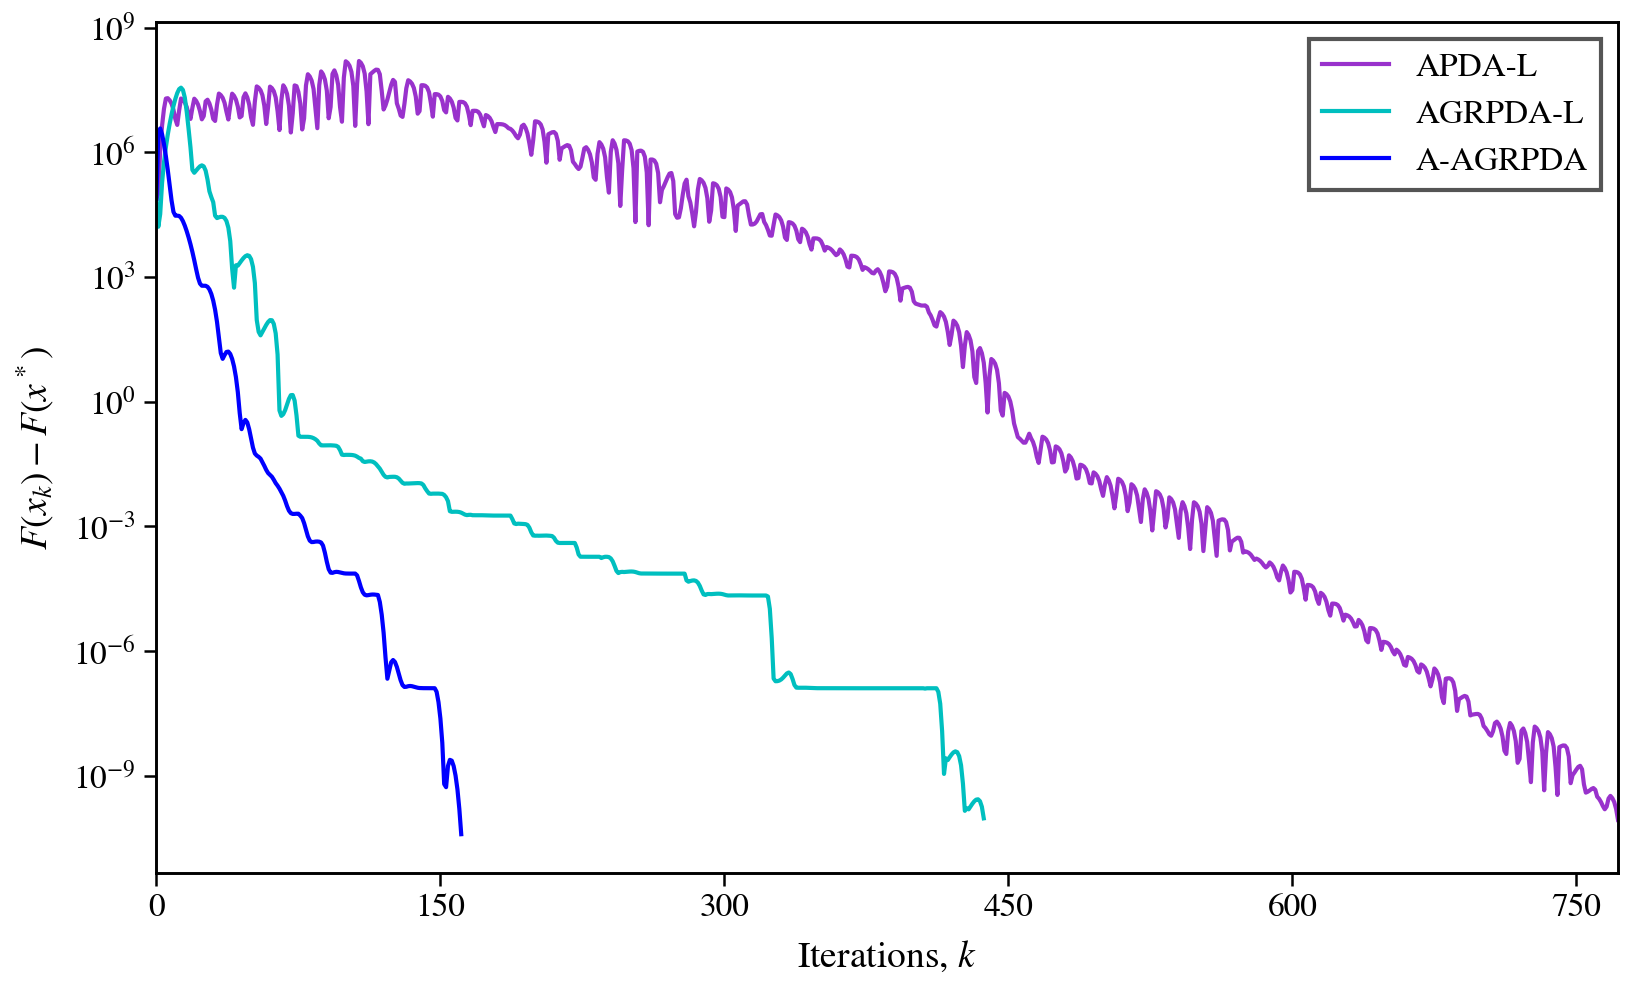

  strong_i, mu=0.3


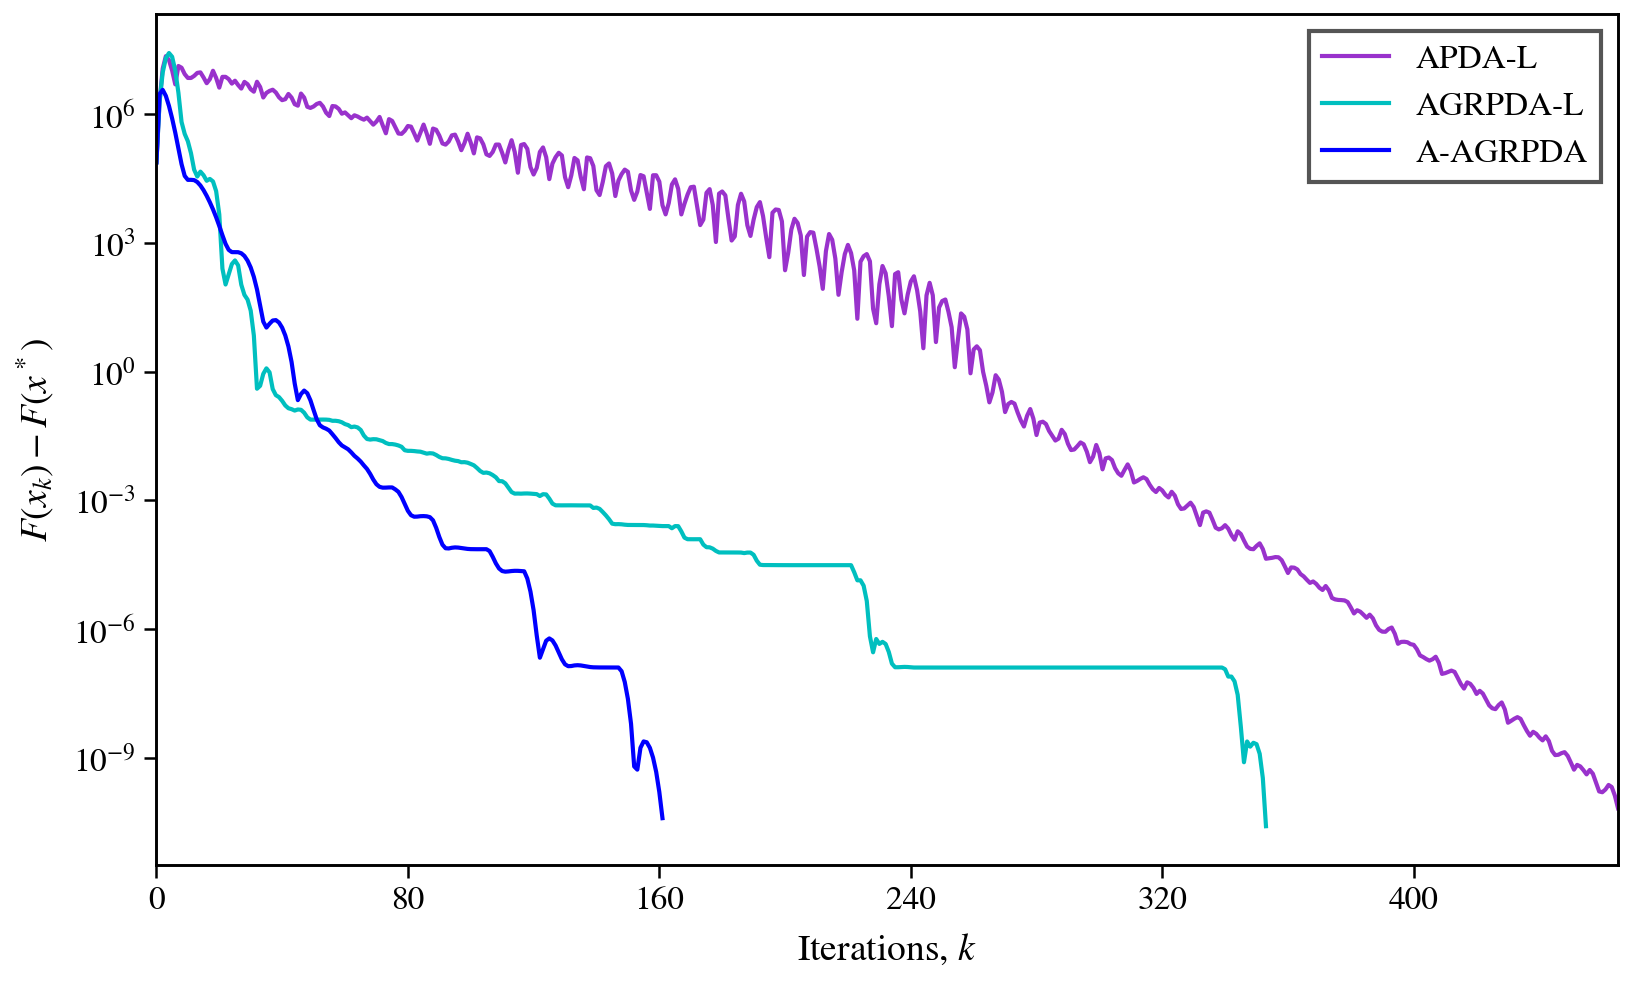

  strong_i, mu=0.7


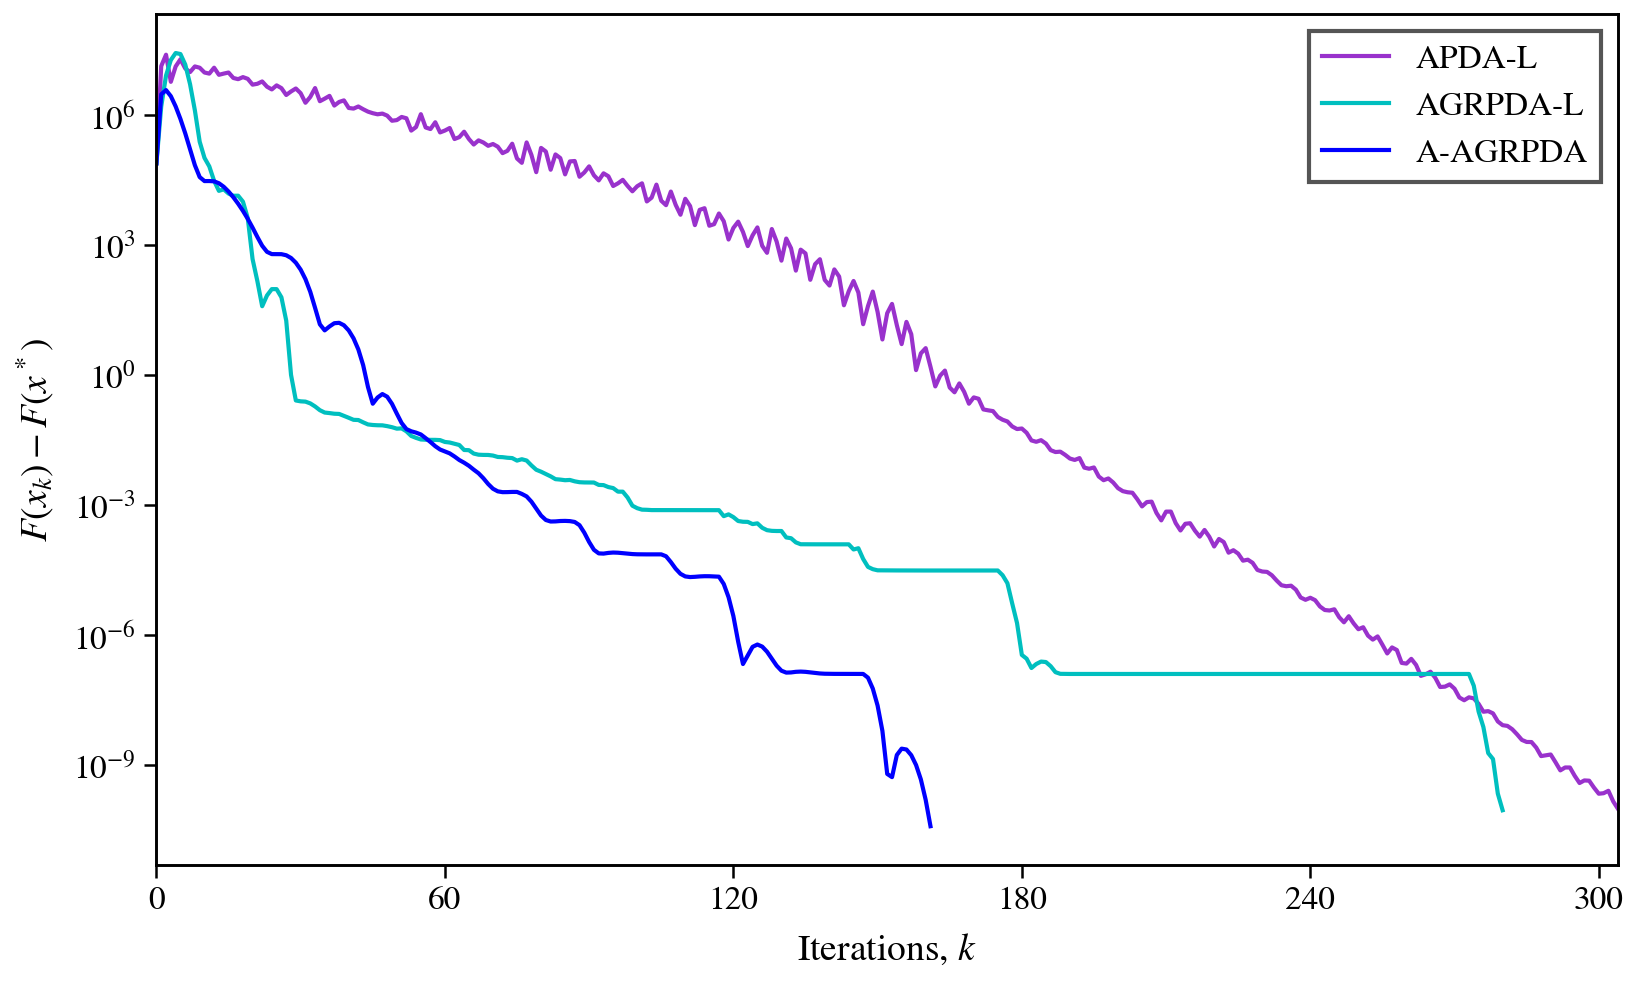

  strong_i, mu=0.9


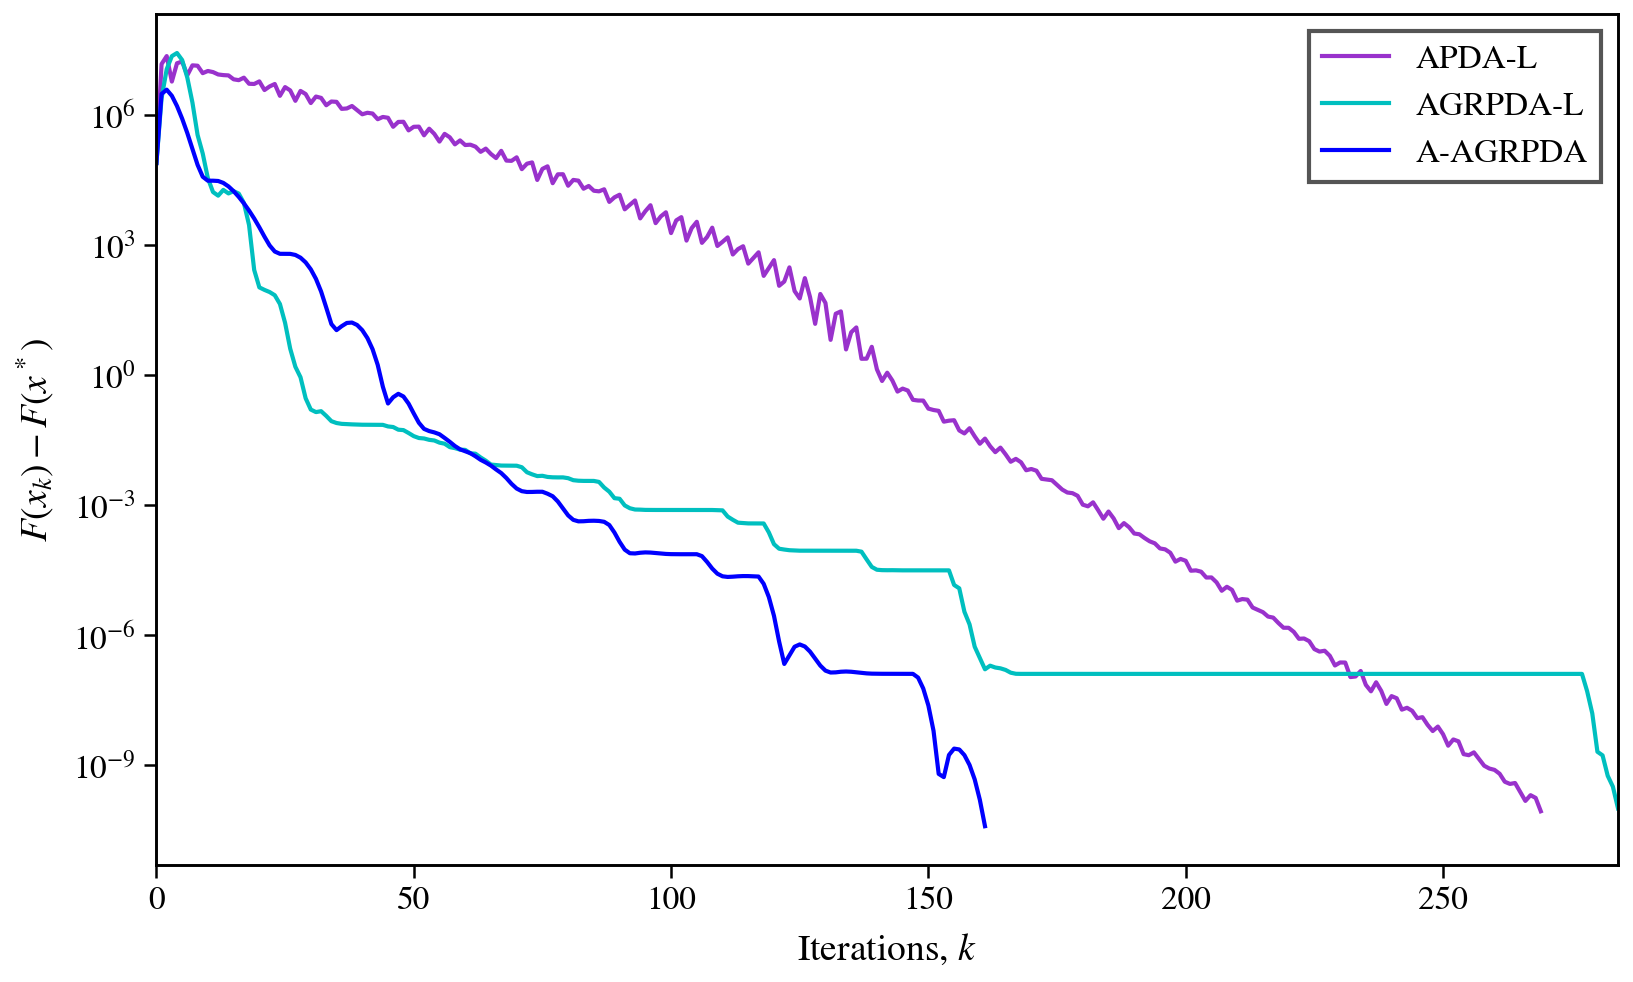

2x2 overview: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity\strong_i\strong_i_mu_three_algorithm_focus_overview.png

Three-algorithm convergence plots for strong_ii_v01:
  strong_ii_v01, mu=0.1


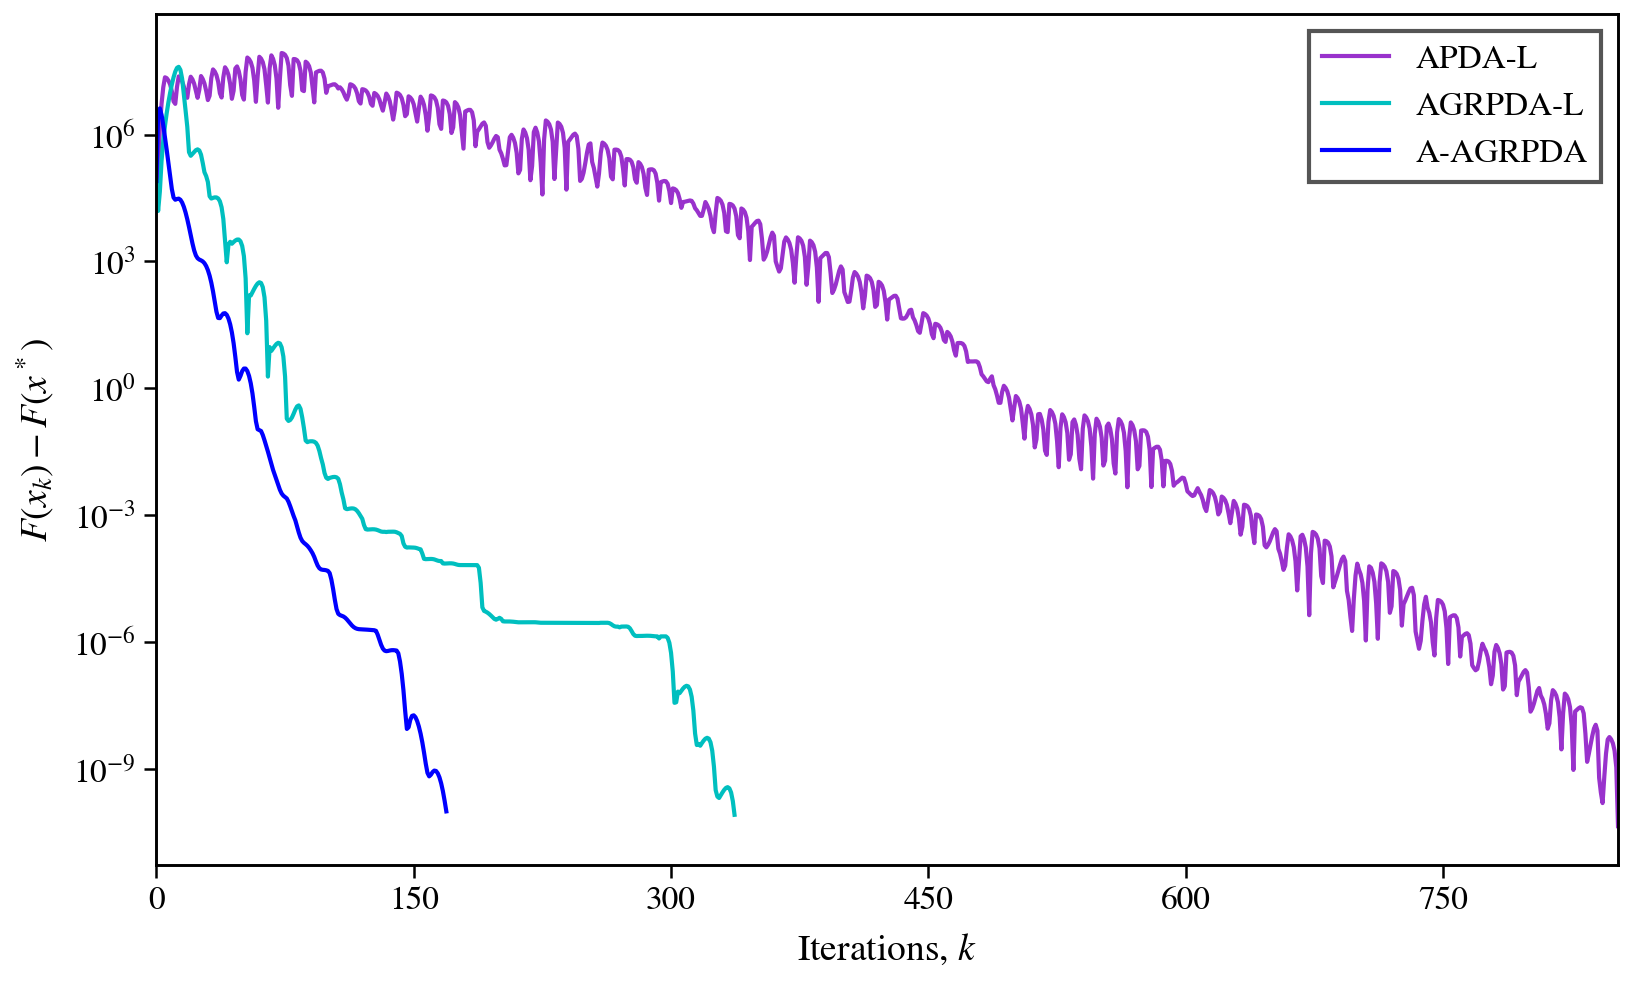

  strong_ii_v01, mu=0.3


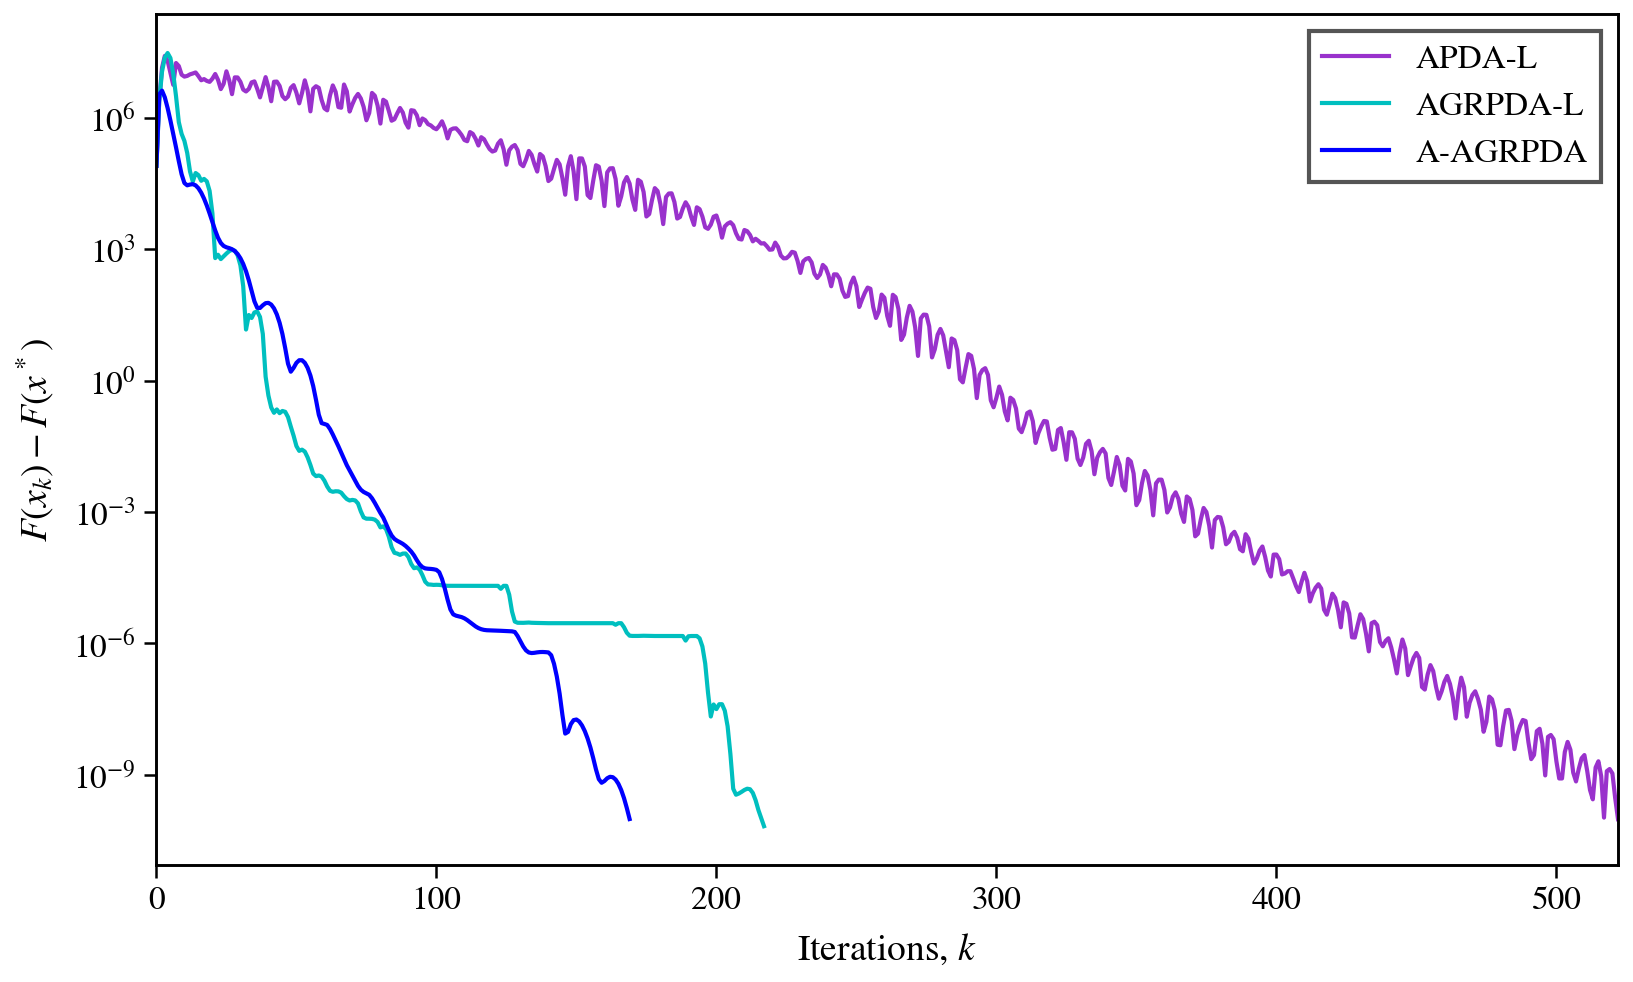

  strong_ii_v01, mu=0.7


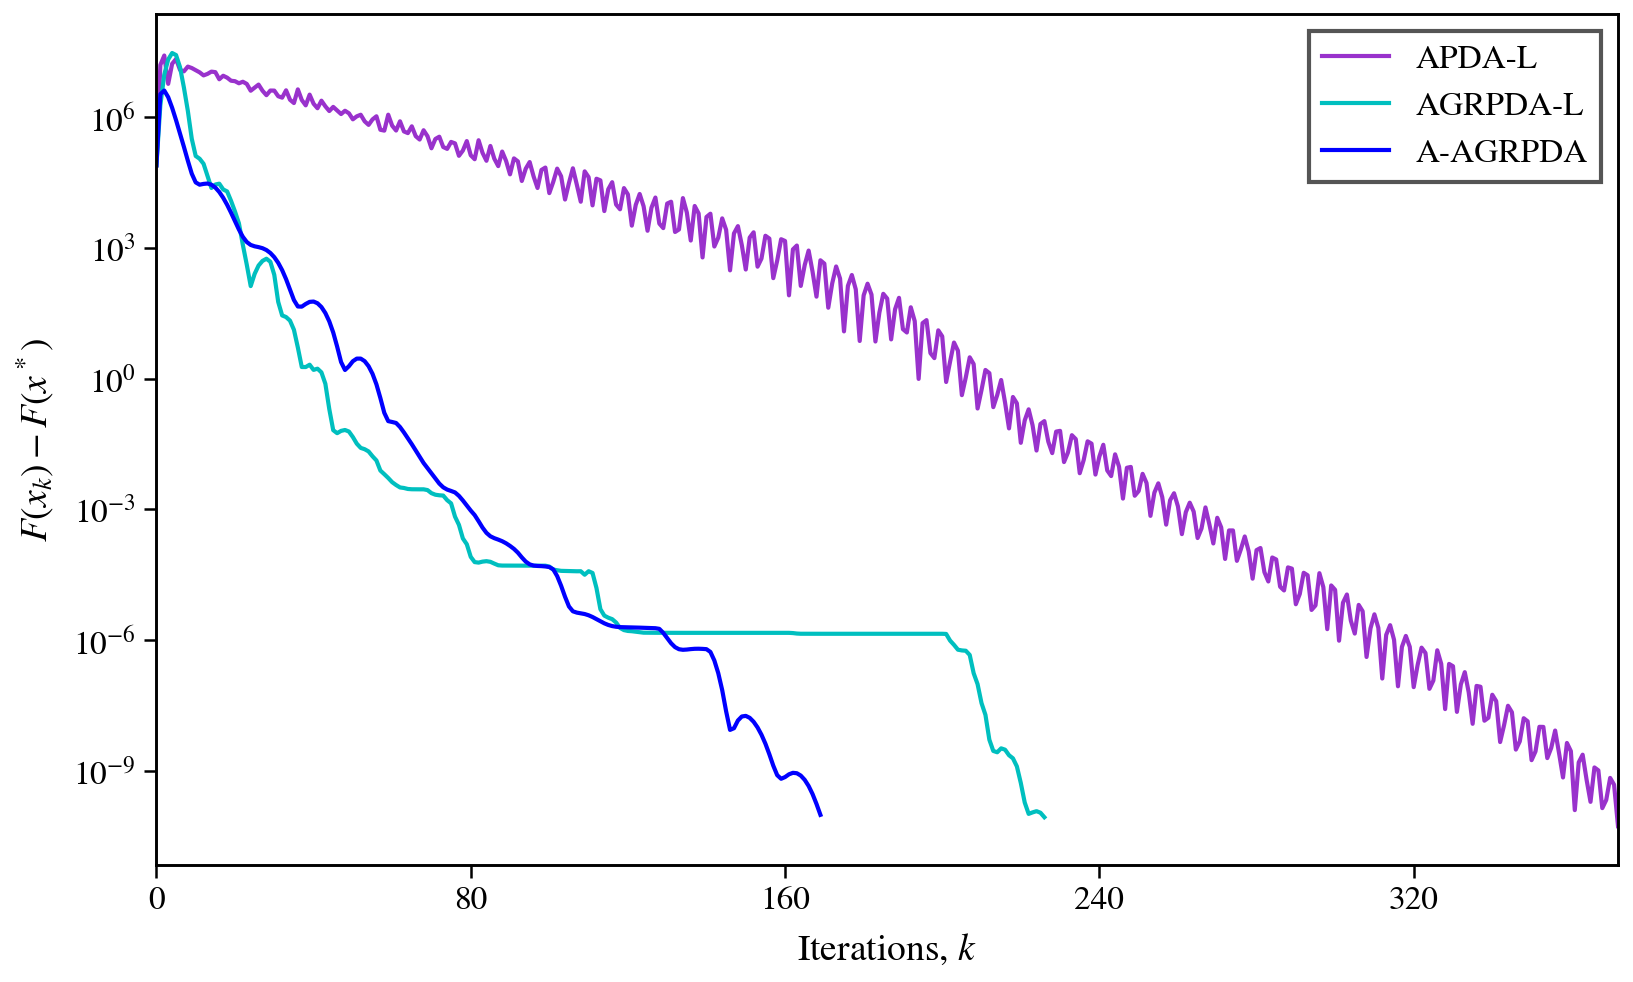

  strong_ii_v01, mu=0.9


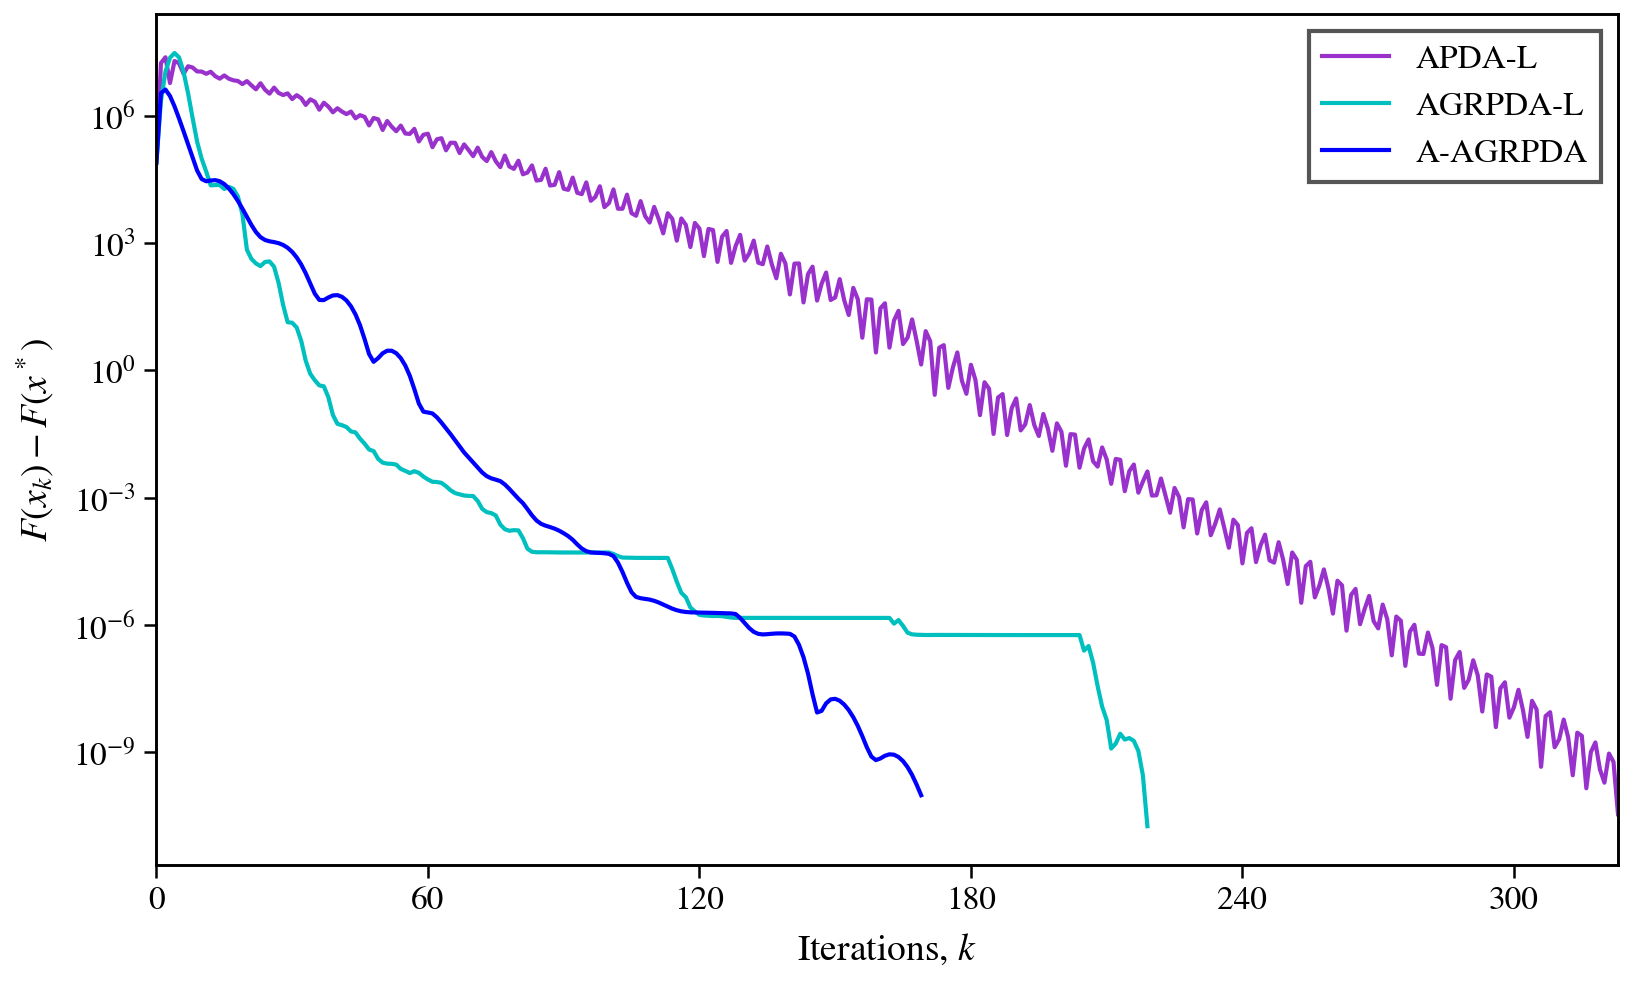

2x2 overview: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity\strong_ii_v01\strong_ii_v01_mu_three_algorithm_focus_overview.png

All individual mu-comparison figures were generated and displayed.
Figure directory: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity


In [13]:
# Run the actual three-algorithm mu experiment and display its saved figures inline.
from IPython.display import display, Image

strong_mu_results, strong_mu_parameter_settings, strong_mu_curves = run_strong_mu_sensitivity()

mu_cols = [
    'Case', 'Mu', 'Algorithm', 'Iter', 'HitIter', 'Reached',
    'CPU_wall_s', 'Avg_ms_per_iter', 'Operator', 'Prox', 'LS',
    'Rejected_LS', 'Operator_per_iter', 'Prox_per_iter', 'LS_per_iter',
    'Final_error', 'mu_applies', 'Is_reused_reference',
    'Was_reused_from_main_comparison'
]
print('\nSTRONG-CONVEX MU SENSITIVITY: THREE-ALGORITHM OBJECTIVE-ERROR COMPARISON')
display(strong_mu_results[mu_cols].round(6))
print('\nSTRONG-CONVEX MU SENSITIVITY: EFFECTIVE PARAMETER SETTINGS')
display(strong_mu_parameter_settings)
print('\nA-AGRPDA is run once per case and reused as the fixed reference at all mu values.')

# These are the actual paths and case IDs created by run_strong_mu_sensitivity().
STRONG_MU_OUT = STRONG_OUT / 'mu_sensitivity'
STRONG_MU_CASES = tuple(spec[0] for spec in STRONG_CASE_SPECS[STRONG_PROFILE])
_EXPECTED_MU_ALGORITHMS = ('A-AGRPDA', 'APDA-L', 'AGRPDA-L')

# Display all eight individual comparison plots (two cases x four mu values).
# Fail loudly if a history or image is missing; do not silently skip the figures.
for case_id in STRONG_MU_CASES:
    case_curves = strong_mu_curves.get(case_id, {})
    if not case_curves:
        raise RuntimeError(
            f'No convergence histories were returned for {case_id}. '
            'The mu experiment did not produce plot data.'
        )
    case_dir = STRONG_MU_OUT / case_id
    print(f'\nThree-algorithm convergence plots for {case_id}:')
    for mu_value in STRONG_MU_SENSITIVITY_VALUES:
        mu_value = float(mu_value)
        panel = case_curves.get(mu_value, {})
        missing = [name for name in _EXPECTED_MU_ALGORITHMS if name not in panel]
        if missing:
            raise RuntimeError(
                f'{case_id}, mu={mu_value:g}: missing histories for {missing}. '
                f'Available histories: {list(panel)}'
            )
        for method in _EXPECTED_MU_ALGORITHMS:
            hist = panel[method]
            if hist is None or hist.empty or not {'Iter', 'F_error'}.issubset(hist.columns):
                raise RuntimeError(
                    f'{case_id}, mu={mu_value:g}: invalid/empty F-error history for {method}.'
                )

        safe_mu = str(mu_value).replace('.', 'p')
        plot_path = case_dir / f'{case_id}_mu_{safe_mu}_three_algorithm_focus.png'
        if not plot_path.is_file() or plot_path.stat().st_size == 0:
            raise FileNotFoundError(
                f'The plotting routine did not create the expected figure: {plot_path}'
            )
        print(f'  {case_id}, mu={mu_value:g}')
        display(Image(filename=str(plot_path)))

    overview = case_dir / f'{case_id}_mu_three_algorithm_focus_overview.png'
    if overview.is_file() and overview.stat().st_size:
        print(f'2x2 overview: {overview}')

print('\nAll individual mu-comparison figures were generated and displayed.')
print('Figure directory:', STRONG_MU_OUT.resolve())


In [14]:
"""General-convex LASSO, A-GRPDA one-factor parameter sensitivity.

Add-on to LASSO_general_5alg_REFERENCE_STYLE.ipynb.  It does not alter
any of the original five comparison algorithms or their saved data.

Parameters: xi_k, eta_k, psi, sigma.  All non-varied settings, the initial
stepsizes, data and starting points are identical to Case (i) A-GRPDA.
No strong-convex or fixed-step E-GRPDA experiments.
"""
from pathlib import Path
import contextlib, io, time as _sens_clock
import numpy as np
import pandas as pd
from scipy.sparse.linalg import svds
from threadpoolctl import threadpool_limits
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, LogLocator, LogFormatterMathtext

SENS_CASE_DEFAULT = 'general_gaussian'
SENS_TOL_DEFAULT = 1e-6
SENS_MAX_ITER_DEFAULT = 10000
BASE_PSI, BASE_SIGMA, BASE_PHI = 1.5, 0.99, 1.4
BASE_BETA_ALGORITHM = 0.2
BASE_BETA_INITIAL_STEP = 5.0  # used only in the initial-step formula

# Keep the base paper settings xi_k=1+1/k^2 and eta_k=1/k^2.
XI_CANDIDATES = (
    (r'$\xi_k=1+k^{-1.1}$',        lambda k: 1. + k**-1.1),
    (r'$\xi_k=1+k^{-3/2}$',        lambda k: 1. + k**-1.5),
    (r'$\xi_k=1+k^{-2}$',          lambda k: 1. + k**-2),
    (r'$\xi_k=1+k^{-3}$',          lambda k: 1. + k**-3),
    (r'$\xi_k=1+2k^{-2}$',         lambda k: 1. + 2.*k**-2),
    (r'$\xi_k=1+2^{-k}$',          lambda k: 1. + 2.**-k),
)
ETA_CANDIDATES = (
    (r'$\eta_k=k^{-1.1}$',         lambda k: k**-1.1),
    (r'$\eta_k=k^{-3/2}$',         lambda k: k**-1.5),
    (r'$\eta_k=k^{-2}$',           lambda k: k**-2),
    (r'$\eta_k=k^{-3}$',           lambda k: k**-3),
    (r'$\eta_k=(2k^2)^{-1}$',      lambda k: .5*k**-2),
    (r'$\eta_k=2^{-k}$',           lambda k: 2.**-k),
)
BASE_XI_INDEX = 2  # 1 + k^{-2}, unchanged main comparison setting
BASE_ETA_INDEX = 2 # k^{-2}, unchanged main comparison setting
PSI_CANDIDATES = (1.1, 1.3, 1.5, 1.6)
SIGMA_CANDIDATES = (0.5, 0.7, 0.9, 0.99)

# Colors are per parameter setting; paper plot style matches the five-algorithm figures.
SENS_COLORS = ('#008000', '#BFBF00', '#BF00BF', '#0000FF', '#D62728', '#00A5A8')


def sens_plot_style():
    mpl.rcParams.update({
        'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix',
        'font.size': 9, 'axes.linewidth': .65,
        'xtick.major.size': 3, 'ytick.major.size': 3,
        'xtick.major.width': .6, 'ytick.major.width': .6,
        'xtick.direction': 'out', 'ytick.direction': 'out',
        'axes.grid': False, 'axes.facecolor': 'white',
        'figure.facecolor': 'white', 'savefig.facecolor': 'white',
        'pdf.fonttype': 42, 'ps.fonttype': 42,
    })


def _setup_options():
    out = {}
    base_xi = XI_CANDIDATES[BASE_XI_INDEX][1]
    base_eta = ETA_CANDIDATES[BASE_ETA_INDEX][1]
    for j, (label, rule) in enumerate(XI_CANDIDATES):
        out[('xi', j)] = dict(label=label, xi=rule, eta=base_eta,
                               psi=BASE_PSI, sigma=BASE_SIGMA)
    for j, (label, rule) in enumerate(ETA_CANDIDATES):
        out[('eta', j)] = dict(label=label, xi=base_xi, eta=rule,
                                psi=BASE_PSI, sigma=BASE_SIGMA)
    for j, psi in enumerate(PSI_CANDIDATES):
        out[('psi', j)] = dict(label=rf'$\psi={psi:g}$', xi=base_xi,
                                 eta=base_eta, psi=psi, sigma=BASE_SIGMA)
    for j, sigma in enumerate(SIGMA_CANDIDATES):
        out[('sigma', j)] = dict(label=rf'$\sigma={sigma:g}$', xi=base_xi,
                                   eta=base_eta, psi=BASE_PSI, sigma=sigma)
    return out


def run_agrpda_sensitivity(algorithm, problem_factory, reference_solver,
                           output_dir, case=SENS_CASE_DEFAULT,
                           tol=SENS_TOL_DEFAULT, max_iter=SENS_MAX_ITER_DEFAULT,
                           norm_factory=None):
    """Run single-factor A-GRPDA sensitivity; no other algorithms are touched.

    Parameters are injected so this runs inside the existing self-contained
    notebook, without importing a second copy of any legacy algorithm.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if not (0 < tol < 1) or max_iter < 1:
        raise ValueError('invalid tolerance or iteration budget')
    rows = []
    cases = _setup_options()
    case_ids = ('xi', 'eta', 'psi', 'sigma')
    with threadpool_limits(limits=1, user_api='blas'):
        A, b, lam = problem_factory(case)
        # The original numerical reference is used for every sensitivity setting.
        ref_csv = output_dir / f'{case}_summary.csv'
        if ref_csv.exists():
            old = pd.read_csv(ref_csv)
            if 'F_reference' in old and len(old):
                Fref = float(old['F_reference'].iloc[0])
            else:
                Fref = float(reference_solver(A, b, lam)[0])
        else:
            Fref = float(reference_solver(A, b, lam)[0])
        if norm_factory is None:
            L = float(svds(A, k=1, which='LM', return_singular_vectors=False,
                           tol=1e-8)[0])
        else:
            L = float(norm_factory(A))
        # IMPORTANT: initial stepsizes are kept FIXED for every setting,
        # including psi and sigma.  This exactly isolates the varied factor.
        tau_init = np.sqrt(BASE_SIGMA*BASE_PHI/(BASE_BETA_INITIAL_STEP*L**2))
        x0 = np.zeros(A.shape[1], dtype=float)
        y0 = -b.copy()
        def px(x, t):
            return np.sign(x)*np.maximum(np.abs(x) - lam*t, 0.)
        def py(y, t):
            return (y-t*b)/(1+t)
        def J(x, y, _):
            r=A @ x-b
            return abs(.5*np.dot(r,r)+lam*np.abs(x).sum()-Fref)

        # Base setting is reused across the four comparisons, not rerun four times.
        class _CountedKT:
            def __init__(self, parent): self.parent=parent
            def dot(self,vec):
                self.parent.nKT += 1
                return self.parent.A.T @ vec
        class _CountedK:
            def __init__(self, mat):
                self.A=mat;self.nK=0;self.nKT=0;self.T=_CountedKT(self)
            def dot(self,vec):
                self.nK+=1
                return self.A @ vec
        curve_cache = {}
        base_key = ('xi', BASE_XI_INDEX)
        for group in case_ids:
            print(f'Parameter sensitivity: {group}', flush=True)
            for j in range(len(XI_CANDIDATES) if group == 'xi' else
                           len(ETA_CANDIDATES) if group == 'eta' else
                           len(PSI_CANDIDATES) if group == 'psi' else
                           len(SIGMA_CANDIDATES)):
                opts=cases[group, j]
                is_base=(group=='xi' and j==BASE_XI_INDEX) or (group=='eta' and j==BASE_ETA_INDEX) \
                        or (group=='psi' and j==2) or (group=='sigma' and j==3)
                key = base_key if is_base else (group,j)
                if key not in curve_cache:
                    op=_CountedK(A)
                    prox_count=[0,0]
                    def cp_x(x,t):
                        prox_count[0]+=1
                        return px(x,t)
                    def cp_y(y,t):
                        prox_count[1]+=1
                        return py(y,t)
                    t0=_sens_clock.perf_counter()
                    with contextlib.redirect_stdout(io.StringIO()):
                        result=algorithm(J,cp_y,cp_x,op,x0,y0,[tau_init,tau_init],
                          BASE_BETA_ALGORITHM,Fref,numb_iter=max_iter,tol=tol,
                          xi_rule=opts['xi'],eta_rule=opts['eta'],
                          psi=opts['psi'],sigma=opts['sigma'],paper_rule=False)
                    elapsed=_sens_clock.perf_counter()-t0
                    vals=np.array(result[0],dtype=float)
                    if np.any(~np.isfinite(vals)):
                        raise FloatingPointError(f'non-finite error: {key}')
                    curve_cache[key]=(vals,elapsed,op.nK,op.nKT,sum(prox_count))
                vals,elapsed,nK,nKT,nProx=curve_cache[key]
                hit_idx=np.flatnonzero(vals<=tol)
                hit=int(hit_idx[0]) if len(hit_idx) else None
                f_name=f'sensitivity_{case}_{group}_{j}_history.csv'
                pd.DataFrame({'Iter':np.arange(len(vals)),'F_error':vals}).to_csv(
                    output_dir/f_name,index=False)
                rows.append(dict(Case=case,Algorithm='A-GRPDA',Parameter=group,
                  Setting=j,Label=opts['label'],Iter=len(vals)-1,
                  HitIter=hit,Reached=hit is not None,CPU_wall_s=elapsed,
                  K_calls=nK,KT_calls=nKT,Operator=nK+nKT,Prox=nProx,LS=0,
                  Final_F_error=float(vals[-1]),Tolerance=tol,
                  MaxIter=max_iter,InitialStep=tau_init,F_reference=Fref,
                  Beta_algorithm=BASE_BETA_ALGORITHM,
                  Beta_initial_step=BASE_BETA_INITIAL_STEP,
                  history_file=f_name))
                print(f'  {opts["label"]}: k={len(vals)-1}, hit={hit}, '
                      f'err={vals[-1]:.3e}, elapsed={elapsed:.2f}s',flush=True)
    df=pd.DataFrame(rows)
    df['Avg_ms_per_iter'] = np.where(df['Iter'] > 0, 1000*df['CPU_wall_s']/df['Iter'], np.nan)
    for col in ('Operator','Prox','LS'):
        df[col+'_per_iter'] = np.where(df['Iter'] > 0, df[col]/df['Iter'], np.nan)
    df['Xi_sequence_fixed'] = r'1+k^{-2}'
    df['Eta_sequence_fixed'] = r'k^{-2}'
    df['Beta'] = BASE_BETA_ALGORITHM  # backward-compatible: algorithmic beta
    df['Beta_algorithm'] = BASE_BETA_ALGORITHM
    df['Beta_initial_step'] = BASE_BETA_INITIAL_STEP
    df['Phi_init'] = BASE_PHI
    df['Psi_base'] = BASE_PSI
    df['Sigma_base'] = BASE_SIGMA
    df.to_csv(output_dir/f'sensitivity_{case}_summary.csv',index=False)
    print('\nSensitivity summary (all six xi and eta settings):')
    print(df[['Parameter','Label','HitIter','Reached','Final_F_error','CPU_wall_s',
              'Avg_ms_per_iter','Operator','Prox','LS']].to_string(index=False))
    return df


def _read_sens_curves(data_dir,case):
    df=pd.read_csv(Path(data_dir)/f'sensitivity_{case}_summary.csv')
    panels={}
    for group in ('xi','eta','psi','sigma'):
        panel=[]
        for _,row in df[df.Parameter==group].sort_values('Setting').iterrows():
            h=pd.read_csv(Path(data_dir)/row.history_file)
            panel.append(dict(label=row.Label,x=h.Iter.to_numpy(dtype=float),
                y=h.F_error.to_numpy(dtype=float),hit=row.HitIter))
        panels[group]=panel
    return panels


def _focus_limit(curves,mode):
    nmax=max(x['x'][-1] for x in curves)
    if mode=='full': return max(1,int(nmax))
    hits=sorted(int(p['hit']) for p in curves if pd.notna(p['hit']))
    if len(hits)>1:
        cutoff=round(1.15*hits[max(0, len(hits)//2)])  # include a majority of the first-hit curves
    elif hits:
        cutoff=round(1.6*hits[0])
    else:
        cutoff=round(.5*nmax)
    return min(int(nmax),max(80,int(cutoff)))


def _sens_panel(ax,curves,mode,caption=None,small=False):
    xcap=_focus_limit(curves,mode)
    for j,c in enumerate(curves):
        mask=c['x']<=xcap
        y=c['y'][mask]
        ax.semilogy(c['x'][mask],np.where(y>0,y,np.nan),
                    lw=.85 if small else .95,ls='-',
                    color=SENS_COLORS[j],label=c['label'])
    ax.set_xlim(0,xcap)
    ax.set_xlabel(r'Iterations, $k$',fontsize=8 if small else 9,labelpad=1)
    ax.set_ylabel(r'$|F(x_k)-F_{\mathrm{ref}}|$',
                  fontsize=8.3 if small else 9.5,labelpad=1)
    ax.grid(False)
    for side in ('top','bottom','left','right'):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(.65)
    ax.tick_params(axis='both',labelsize=7 if small else 8,
                   length=2.3,width=.55)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4,integer=True))
    ax.yaxis.set_major_locator(LogLocator(base=10,numticks=7))
    ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.legend(loc='upper right',fontsize=5.6 if small else 6.5,
        ncol=2 if len(curves)>4 else 1,
        frameon=True,fancybox=False,framealpha=1,
        edgecolor='#555555',facecolor='white',
        handlelength=1.7,borderpad=.25,labelspacing=.16,
        borderaxespad=.2)
    if caption:
        ax.text(.5,-.26,caption,ha='center',va='top',
                transform=ax.transAxes,fontsize=10 if small else 11)


def plot_agrpda_sensitivity(data_dir,case=SENS_CASE_DEFAULT,
                            mode='focus',show=False):
    """Create 4 parameter-group plots and a 2x2 summary, matching reference styling."""
    data_dir=Path(data_dir)
    curves=_read_sens_curves(data_dir,case)
    sens_plot_style()
    names={'xi':r'(a) $\xi_k$','eta':r'(b) $\eta_k$',
           'psi':r'(c) $\psi$','sigma':r'(d) $\sigma$'}
    for group,cs in curves.items():
        fig,ax=plt.subplots(figsize=(4.55,3.1))
        fig.subplots_adjust(left=.16,right=.965,top=.96,bottom=.30)
        _sens_panel(ax,cs,mode,names[group])
        stem=data_dir/f'figure_sensitivity_{case}_{group}_{mode}'
        for ext in ('pdf','png'):
            fig.savefig(stem.with_suffix('.'+ext),dpi=240,
                        bbox_inches='tight',pad_inches=.06)
        if show: plt.show()
        plt.close(fig)
    fig,axes=plt.subplots(2,2,figsize=(9.4,6.9))
    fig.subplots_adjust(left=.105,right=.985,top=.98,bottom=.12,
                        wspace=.30,hspace=.53)
    for ax,group in zip(axes.flat,('xi','eta','psi','sigma')):
        _sens_panel(ax,curves[group],mode,names[group],small=True)
    stem=data_dir/f'figure_sensitivity_{case}_four_panels_{mode}'
    for ext in ('pdf','png'):
        fig.savefig(stem.with_suffix('.'+ext),dpi=240,
                    bbox_inches='tight',pad_inches=.06)
    if show:plt.show()
    plt.close(fig)
    print('Saved sensitivity plots:',stem.with_suffix('.pdf'),flush=True)



Parameter sensitivity: xi
  $\xi_k=1+k^{-1.1}$: k=512, hit=512, err=9.034e-07, elapsed=1.08s
  $\xi_k=1+k^{-3/2}$: k=494, hit=494, err=7.380e-07, elapsed=1.06s
  $\xi_k=1+k^{-2}$: k=475, hit=475, err=9.304e-07, elapsed=1.07s
  $\xi_k=1+k^{-3}$: k=475, hit=475, err=9.077e-07, elapsed=1.02s
  $\xi_k=1+2k^{-2}$: k=478, hit=478, err=9.917e-07, elapsed=1.05s
  $\xi_k=1+2^{-k}$: k=475, hit=475, err=8.910e-07, elapsed=1.06s
Parameter sensitivity: eta
  $\eta_k=k^{-1.1}$: k=487, hit=487, err=9.997e-07, elapsed=1.11s
  $\eta_k=k^{-3/2}$: k=483, hit=483, err=7.381e-07, elapsed=1.00s
  $\eta_k=k^{-2}$: k=475, hit=475, err=9.304e-07, elapsed=1.07s
  $\eta_k=k^{-3}$: k=470, hit=470, err=8.278e-07, elapsed=0.98s
  $\eta_k=(2k^2)^{-1}$: k=477, hit=477, err=9.389e-07, elapsed=0.99s
  $\eta_k=2^{-k}$: k=740, hit=740, err=9.183e-07, elapsed=1.57s
Parameter sensitivity: psi
  $\psi=1.1$: k=611, hit=611, err=8.498e-07, elapsed=1.25s
  $\psi=1.3$: k=564, hit=564, err=9.353e-07, elapsed=1.18s
  $\psi=1.5$: 

,Parameter,Label,HitIter,Reached,Final_F_error,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS
0,xi,$\xi_k=1+k^{-1.1}$,512,True,9.034397e-07,1.079411,2.108225,1026,1024,0
1,xi,$\xi_k=1+k^{-3/2}$,494,True,7.380223e-07,1.063562,2.152959,990,988,0
2,xi,$\xi_k=1+k^{-2}$,475,True,9.303970e-07,1.066792,2.245877,952,950,0
3,xi,$\xi_k=1+k^{-3}$,475,True,9.076656e-07,1.016343,2.139669,952,950,0
4,xi,$\xi_k=1+2k^{-2}$,478,True,9.917155e-07,1.050728,2.198175,958,956,0
5,xi,$\xi_k=1+2^{-k}$,475,True,8.910450e-07,1.063231,2.238381,952,950,0
6,eta,$\eta_k=k^{-1.1}$,487,True,9.997080e-07,1.110635,2.280566,976,974,0
7,eta,$\eta_k=k^{-3/2}$,483,True,7.381006e-07,1.000161,2.070726,968,966,0
8,eta,$\eta_k=k^{-2}$,475,True,9.303970e-07,1.066792,2.245877,952,950,0
9,eta,$\eta_k=k^{-3}$,470,True,8.277945e-07,0.983717,2.093016,942,940,0


Saved sensitivity plots: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_sensitivity_general_gaussian_four_panels_focus.pdf
Saved sensitivity plots: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\figure_sensitivity_general_gaussian_four_panels_full.pdf


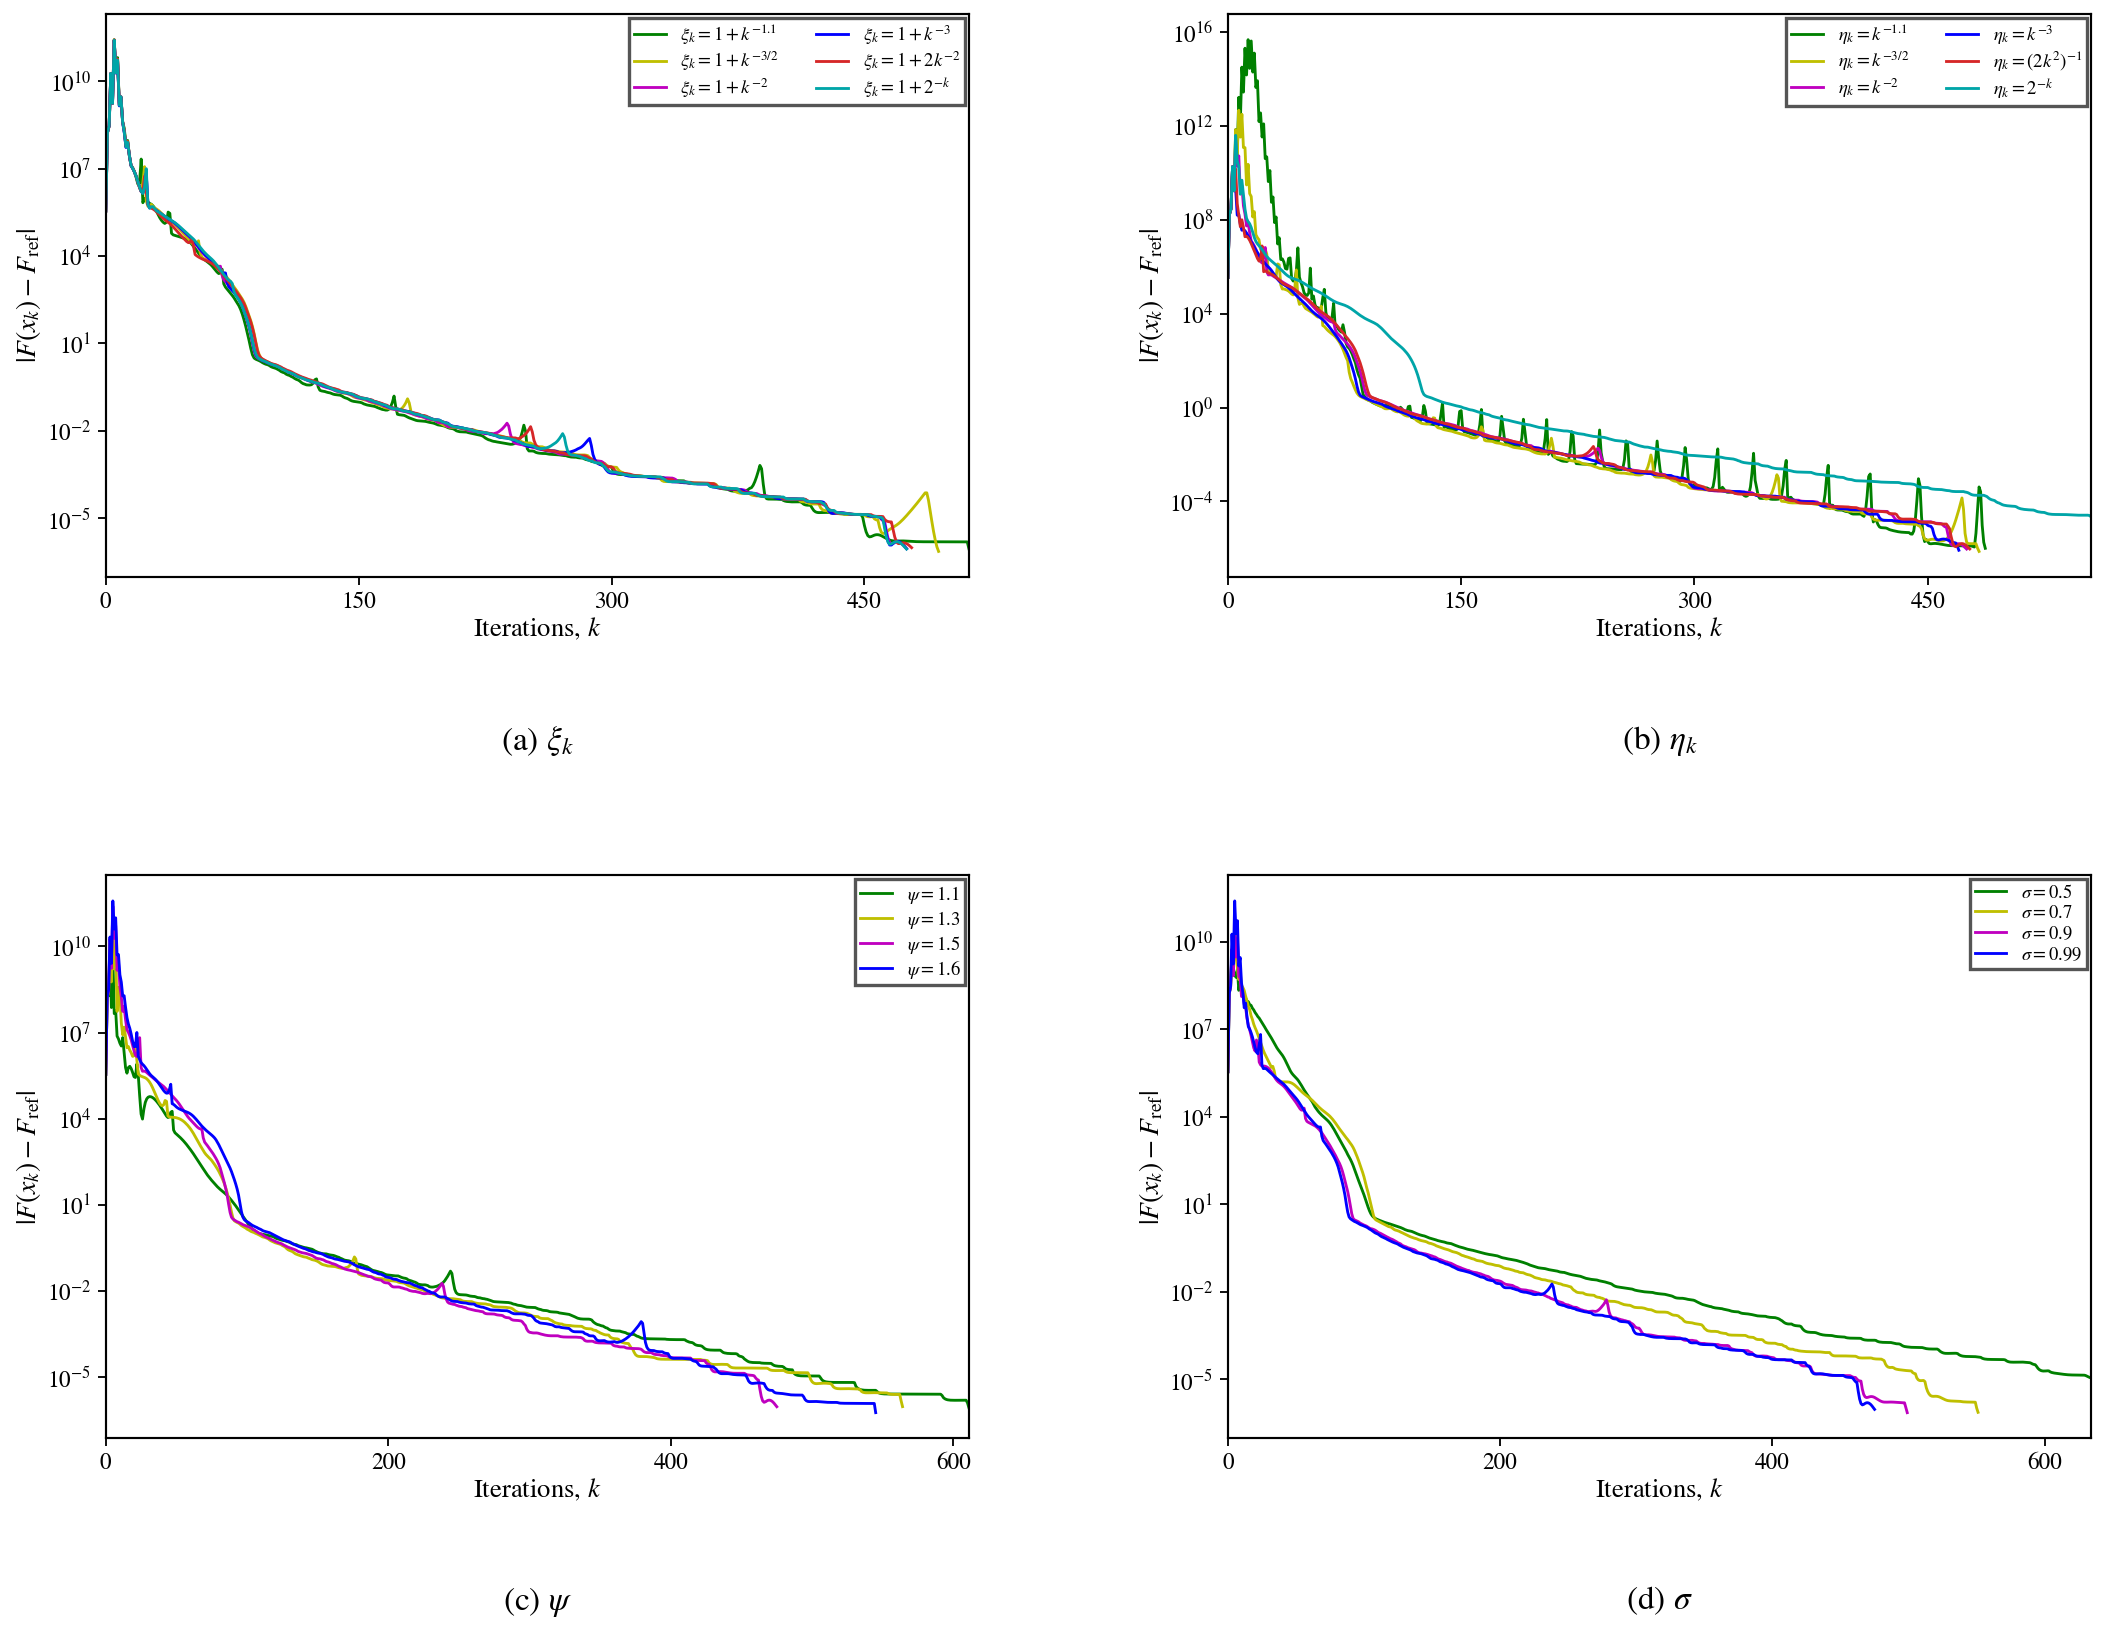

In [15]:
from IPython.display import display, Image
SENS_CASE = 'general_gaussian'  # Case (i); change only if a different case is needed
SENS_OUTPUT = Path.cwd() / 'results'

# Uses the already-defined original A-GRPDA, case generator and reference solver.
sensitivity_summary = run_agrpda_sensitivity(
    pd_adaptive_Golden1, make_problem, ref_value, output_dir=SENS_OUTPUT,
    case=SENS_CASE, tol=1e-6, max_iter=10000,
)
display(sensitivity_summary[
    ['Parameter','Label','HitIter','Reached','Final_F_error','CPU_wall_s',
     'Avg_ms_per_iter','Operator','Prox','LS']
])

# Full sample history is preserved; focus changes the visible x-axis only.
plot_agrpda_sensitivity(SENS_OUTPUT, case=SENS_CASE, mode='focus')
plot_agrpda_sensitivity(SENS_OUTPUT, case=SENS_CASE, mode='full')
display(Image(filename=str(SENS_OUTPUT /
    f'figure_sensitivity_{SENS_CASE}_four_panels_focus.png')))


In [16]:
from pathlib import Path
from IPython.display import display
import json
import pandas as pd
import numpy as np

OUT_ROOT = Path.cwd() / 'results'
OUT_ROOT.mkdir(exist_ok=True)

def _safe_csv(path):
    return pd.read_csv(path) if Path(path).is_file() else pd.DataFrame()

G_OBJ = _safe_csv(OUT_ROOT/'comparison_summary.csv')
G_GAP = _safe_csv(OUT_ROOT/'pdgap_comparison_summary.csv')
S_ALL = _safe_csv(OUT_ROOT/'strong_convex'/'strong_all_metrics_and_costs.csv')
S_PAR = _safe_csv(OUT_ROOT/'strong_convex'/'strong_algorithm_parameter_settings.csv')
S_MU = _safe_csv(OUT_ROOT/'strong_convex'/'mu_sensitivity'/'strong_mu_sensitivity_all_metrics.csv')
S_MU_PAR = _safe_csv(OUT_ROOT/'strong_convex'/'mu_sensitivity'/'strong_mu_sensitivity_parameter_settings.csv')
S_SENS = _safe_csv(OUT_ROOT/'sensitivity_general_gaussian_summary.csv')

summary_rows = []
for metric,df in [('F_error',G_OBJ),('PD_gap',G_GAP)]:
    for _, r in df.iterrows():
        n=float(r['Iter'])
        cpu=float(r['CPU_wall_s'])
        summary_rows.append(dict(Family='general',Experiment='main_comparison',Mu=np.nan,
            Case=r['Case'],Algorithm=r['Algorithm'],
            Metric=metric,Iter=int(n),Reached=bool(r['Reached']),
            CPU_wall_s=cpu,Avg_ms_per_iter=1000*cpu/n if n else np.nan,
            Operator=int(r['Operator']),Prox=int(r['Prox']),LS=int(r['LS']),
            Operator_per_iter=float(r['Operator'])/n if n else np.nan,
            Prox_per_iter=float(r['Prox'])/n if n else np.nan,
            LS_per_iter=float(r['LS'])/n if n else np.nan,
            Final_error=float(r['F_error'] if metric=='F_error' else r['Gap']),
            Tolerance=float(r['Tolerance'] if metric=='F_error' else r['Gap_tolerance']),
            Beta_algorithm=float(r.get('Beta_algorithm',np.nan)),
            Beta_initial_step=float(r.get('Beta_initial_step',np.nan))))
for _,r in S_ALL.iterrows():
    row={k:r.get(k,np.nan) for k in (
        'Family','Case','Algorithm','Metric','Iter','Reached','CPU_wall_s',
        'Avg_ms_per_iter','Operator','Prox','LS','Operator_per_iter',
        'Prox_per_iter','LS_per_iter','Final_error','Tolerance')}
    row.update(Experiment='main_comparison',Mu=np.nan)
    summary_rows.append(row)
for _,r in S_MU.iterrows():
    row={k:r.get(k,np.nan) for k in (
        'Family','Case','Algorithm','Metric','Iter','HitIter','Reached','CPU_wall_s',
        'Avg_ms_per_iter','Operator','Prox','LS','Operator_per_iter',
        'Prox_per_iter','LS_per_iter','Final_error','Tolerance')}
    row.update(Experiment='mu_sensitivity',Mu=float(r['Mu']))
    summary_rows.append(row)
master=pd.DataFrame(summary_rows)
GENERAL_ALGORITHM_ORDER=('GRPDA','PDA-L','GRPDA-L','P-GRPDA','A-GRPDA')
STRONG_ALGORITHM_ORDER=('APDA-L','AGRPDA-L','A-AGRPDA')
_algorithm_rank={name:i for i,name in enumerate(GENERAL_ALGORITHM_ORDER)}
_algorithm_rank.update({name:i for i,name in enumerate(STRONG_ALGORITHM_ORDER)})
if not master.empty:
    master['_family_rank']=master['Family'].map({'general':0,'strong':1}).fillna(9)
    master['_experiment_rank']=master['Experiment'].map({'main_comparison':0,'mu_sensitivity':1}).fillna(9)
    master['_metric_rank']=master['Metric'].map({'F_error':0,'PD_gap':1}).fillna(9)
    master['_algorithm_rank']=master['Algorithm'].map(_algorithm_rank).fillna(99)
    master=master.sort_values(['_family_rank','Case','_experiment_rank','_metric_rank','_algorithm_rank','Mu'],kind='stable')
    master=master.drop(columns=['_family_rank','_experiment_rank','_metric_rank','_algorithm_rank']).reset_index(drop=True)
master.to_csv(OUT_ROOT/'all_general_and_strong_algorithm_results.csv',index=False)

G_PAR=[]
for case in CASES:
    p=OUT_ROOT/f'{case}_summary.csv'
    if not p.is_file():
        continue
    row=pd.read_csv(p).iloc[0]
    # Data from exactly the existing main-run formula, not new parameter choices.
    A,b,lam=make_problem(case)
    from scipy.sparse.linalg import svds
    L=float(svds(A,k=1,which='LM',return_singular_vectors=False,
                 tol=1e-8,v0=np.ones(min(A.shape))/np.sqrt(min(A.shape)))[0])
    np.random.seed(100)
    delta=1e-12*np.random.random(b.shape)
    zeta=float(np.linalg.norm(delta)/np.linalg.norm(A.T@delta))
    beta_linesearch=5.0
    beta_agrpda_algorithm=0.2
    beta_agrpda_initial_step=5.0
    phi=1.4
    cfgs={
      'GRPDA':dict(sigma=.05*np.sqrt(phi)/L,tau0=2*zeta/np.sqrt(beta_linesearch),phi=phi,
                   stepsize_source='global_norm_L'),
      'PDA-L':dict(tau0=zeta/np.sqrt(beta_linesearch),beta_arg=1/beta_linesearch,
                   mu=GENERAL_LINESEARCH_MU,delta=.99,stepsize_source='direction_zeta'),
      'GRPDA-L':dict(tau0=zeta/np.sqrt(beta_linesearch),beta_arg=1/beta_linesearch,
                     phi_internal=1.5,mu=GENERAL_LINESEARCH_MU,delta=.99,stepsize_source='direction_zeta'),
      'P-GRPDA':dict(tau0=10.,beta=.2,psi=1.76,mu=.77236,muprime=.26,
                      stepsize_source='norm_free'),
      'A-GRPDA':dict(tau0=np.sqrt(.99*phi/(beta_agrpda_initial_step*L*L)),
                      tau1=np.sqrt(.99*phi/(beta_agrpda_initial_step*L*L)),
                      beta=beta_agrpda_algorithm,
                      beta_initial_step=beta_agrpda_initial_step,
                      psi=1.5,sigma=.99,xi='1+k^(-2)',eta='k^(-2)',
                      paper_rule=False,stepsize_source='global_norm_L'),
    }
    for name,cfg in cfgs.items():
        G_PAR.append(dict(Family='general',Case=case,Algorithm=name,
                          Rows=A.shape[0],Cols=A.shape[1],lambda_reg=lam,
                          L=L,zeta=zeta,**cfg))
params_general=pd.DataFrame(G_PAR)
params_general.to_csv(OUT_ROOT/'general_algorithm_parameter_settings.csv',index=False)
if not S_MU_PAR.empty:
    S_MU_PAR = S_MU_PAR.copy()
    S_MU_PAR['Experiment'] = 'mu_sensitivity'
    S_PAR = S_PAR.copy()
    if not S_PAR.empty:
        S_PAR['Experiment'] = 'main_comparison'
params_all=pd.concat([params_general,S_PAR,S_MU_PAR],ignore_index=True,sort=False)
if 'Mu' not in params_all.columns:
    params_all['Mu']=np.nan
if 'Experiment' not in params_all.columns:
    params_all['Experiment']='main_comparison'
if not params_all.empty:
    params_all['_family_rank']=params_all['Family'].map({'general':0,'strong':1}).fillna(9)
    params_all['_algorithm_rank']=params_all['Algorithm'].map(_algorithm_rank).fillna(99)
    params_all['_experiment_rank']=params_all.get('Experiment',pd.Series(index=params_all.index,dtype=object)).map({'main_comparison':0,'mu_sensitivity':1}).fillna(9)
    params_all=params_all.sort_values(['_family_rank','Case','_experiment_rank','_algorithm_rank','Mu'],kind='stable')
    params_all=params_all.drop(columns=['_family_rank','_algorithm_rank','_experiment_rank']).reset_index(drop=True)
params_all.to_csv(OUT_ROOT/'all_algorithm_parameter_settings.csv',index=False)

settings=dict(
 general_cases=list(CASES),general_max_iter=MAX_ITER,general_objective_tolerance=TOL,
 general_gap_max_iter=MAX_ITER_GAP,general_gap_tolerance=GAP_TOL,
 general_linesearch_mu=GENERAL_LINESEARCH_MU,
 general_agrpda_algorithm_beta=0.2,
 general_agrpda_initial_step_beta=5.0,
 strong_profile=STRONG_PROFILE,strong_source_library='methods/*.py',
 strong_main_max_iter=STRONG_MAIN_MAX_ITER,strong_main_tolerance=STRONG_MAIN_TOL,
 strong_gap_max_iter=STRONG_GAP_MAX_ITER,strong_gap_tolerance=STRONG_GAP_TOL,
 strong_reference_mode=STRONG_REFERENCE_MODE,strong_reference_iterations=STRONG_REF_ITER,
 strong_mu=STRONG_MU,strong_mu_sensitivity_values=list(STRONG_MU_SENSITIVITY_VALUES),
 strong_mu_sensitivity_methods=list(STRONG_MU_METHODS),
 strong_mu_sensitivity_line_search_methods=list(STRONG_MU_LINESEARCH_METHODS),
 strong_mu_sensitivity_fixed_baseline=STRONG_MU_BASELINE_METHOD,
 strong_mu_sensitivity_output='strong_convex/mu_sensitivity',
 strong_cases=[list(x) for x in STRONG_CASE_SPECS[STRONG_PROFILE]],
 sensitivity_case=SENS_CASE,sensitivity_tolerance=SENS_TOL_DEFAULT,
 sensitivity_max_iter=SENS_MAX_ITER_DEFAULT,
 xi_options=[label for label,_ in XI_CANDIDATES],
 eta_options=[label for label,_ in ETA_CANDIDATES],
 psi_options=list(PSI_CANDIDATES),sigma_options=list(SIGMA_CANDIDATES),
 sensitivity_base_xi_index=BASE_XI_INDEX,sensitivity_base_eta_index=BASE_ETA_INDEX)
(OUT_ROOT/'experiment_settings.json').write_text(
    json.dumps(settings,ensure_ascii=False,indent=2),encoding='utf-8')
print('GENERAL + STRONG: objective and PD-gap comparison results')
display(master[['Family','Experiment','Case','Algorithm','Mu','Metric','Iter','Reached',
                'CPU_wall_s','Avg_ms_per_iter','Operator','Prox','LS',
                'Operator_per_iter','Prox_per_iter','LS_per_iter','Final_error',
                'Beta_algorithm','Beta_initial_step']])
print('STRONG-CONVEX: separate common-mu sensitivity results')
if not S_MU.empty:
    display(S_MU[['Case','Algorithm','Mu','Metric','Iter','HitIter','Reached','CPU_wall_s',
                  'Avg_ms_per_iter','Operator','Prox','LS','Final_error']])
print('GENERAL + STRONG: effective parameter values')
display(params_all)
print('Sensitivity options and results:')
if not S_SENS.empty:
    display(S_SENS[['Parameter','Label','HitIter','Reached','Final_F_error',
                    'CPU_wall_s','Avg_ms_per_iter','Operator','Prox','LS']])
print('Saved:',OUT_ROOT/'all_general_and_strong_algorithm_results.csv')
print('Saved:',OUT_ROOT/'all_algorithm_parameter_settings.csv')
print('Saved:',OUT_ROOT/'strong_convex'/'mu_sensitivity'/'strong_mu_sensitivity_all_metrics.csv')
print('Saved:',OUT_ROOT/'strong_convex'/'mu_sensitivity'/'strong_mu_sensitivity_parameter_settings.csv')
print('Saved:',OUT_ROOT/'experiment_settings.json')


GENERAL + STRONG: objective and PD-gap comparison results


,Family,Experiment,Case,Algorithm,Mu,Metric,Iter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Operator_per_iter,Prox_per_iter,LS_per_iter,Final_error,Beta_algorithm,Beta_initial_step
0,general,main_comparison,general_gaussian,GRPDA,NaN,F_error,12526,True,28.282085,2.257870,25052,25052,0,2.000000,2.000000,0.000000,9.166001e-13,NaN,NaN
1,general,main_comparison,general_gaussian,PDA-L,NaN,F_error,2225,True,4.856895,2.182874,4454,4822,2597,2.001798,2.167191,1.167191,4.902745e-13,0.2,NaN
2,general,main_comparison,general_gaussian,GRPDA-L,NaN,F_error,1392,True,2.855601,2.051438,2786,2847,1455,2.001437,2.045259,1.045259,9.308110e-13,0.2,NaN
3,general,main_comparison,general_gaussian,P-GRPDA,NaN,F_error,2281,True,3.405104,1.492812,4562,4562,0,2.000000,2.000000,0.000000,8.952838e-13,0.2,NaN
4,general,main_comparison,general_gaussian,A-GRPDA,NaN,F_error,1012,True,2.086582,2.061840,2026,2024,0,2.001976,2.000000,0.000000,9.308110e-13,0.2,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,strong,mu_sensitivity,strong_ii_v01,AGRPDA-L,0.9,F_error,219,True,0.042101,0.192241,1084,864,645,4.949772,3.945205,2.945205,1.812239e-11,NaN,NaN
62,strong,mu_sensitivity,strong_ii_v01,A-AGRPDA,0.1,F_error,169,True,0.021829,0.129169,508,338,0,3.005917,2.000000,0.000000,9.719514e-11,NaN,NaN
63,strong,mu_sensitivity,strong_ii_v01,A-AGRPDA,0.3,F_error,169,True,0.021829,0.129169,508,338,0,3.005917,2.000000,0.000000,9.719514e-11,NaN,NaN
64,strong,mu_sensitivity,strong_ii_v01,A-AGRPDA,0.7,F_error,169,True,0.021829,0.129169,508,338,0,3.005917,2.000000,0.000000,9.719514e-11,NaN,NaN


STRONG-CONVEX: separate common-mu sensitivity results


,Case,Algorithm,Mu,Metric,Iter,HitIter,Reached,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS,Final_error
0,strong_i,APDA-L,0.1,F_error,772,772,True,0.112960,0.146321,4093,1660,888,8.549250e-11
1,strong_i,AGRPDA-L,0.1,F_error,437,437,True,0.045139,0.103292,1351,913,476,9.354295e-11
2,strong_i,A-AGRPDA,0.1,F_error,161,161,True,0.017204,0.106855,484,322,0,3.882406e-11
3,strong_i,APDA-L,0.3,F_error,465,465,True,0.063895,0.137408,2592,1063,598,6.591705e-11
4,strong_i,AGRPDA-L,0.3,F_error,353,353,True,0.045032,0.127568,1120,766,413,2.522427e-11
5,strong_i,A-AGRPDA,0.3,F_error,161,161,True,0.017204,0.106855,484,322,0,3.882406e-11
6,strong_i,APDA-L,0.7,F_error,304,304,True,0.051392,0.169054,2105,900,596,9.713119e-11
7,strong_i,AGRPDA-L,0.7,F_error,280,280,True,0.040612,0.145042,1003,722,442,9.058709e-11
8,strong_i,A-AGRPDA,0.7,F_error,161,161,True,0.017204,0.106855,484,322,0,3.882406e-11
9,strong_i,APDA-L,0.9,F_error,269,269,True,0.069903,0.259861,3086,1408,1139,8.574830e-11


GENERAL + STRONG: effective parameter values


,Family,Profile,Case,Algorithm,Reference_method,tau0,beta0,gamma,mu,phi,...,psi,sigma,paper_rule,xi,eta,Experiment,Mu,mu_applies,Is_reused_reference,Was_reused_from_main_comparison
0,strong,original_code,strong_i,APDA-L,original_source_two_algorithm,0.048837,0.50,1.00,0.3,1.4,...,NaN,NaN,NaN,NaN,NaN,main_comparison,NaN,NaN,NaN,NaN
1,strong,original_code,strong_i,AGRPDA-L,original_source_two_algorithm,0.199375,0.45,0.01,0.3,1.4,...,NaN,NaN,NaN,NaN,NaN,main_comparison,NaN,NaN,NaN,NaN
2,strong,original_code,strong_i,A-AGRPDA,original_source_two_algorithm,0.119473,0.10,0.01,NaN,NaN,...,1.5,0.99,False,not applicable,not applicable,main_comparison,NaN,NaN,NaN,NaN
3,strong,original_code,strong_i,APDA-L,NaN,0.048837,0.50,1.00,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.1,True,False,False
4,strong,original_code,strong_i,APDA-L,NaN,0.048837,0.50,1.00,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.3,True,False,False
5,strong,original_code,strong_i,APDA-L,NaN,0.048837,0.50,1.00,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.7,True,False,False
6,strong,original_code,strong_i,APDA-L,NaN,0.048837,0.50,1.00,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.9,True,False,False
7,strong,original_code,strong_i,AGRPDA-L,NaN,0.199375,0.45,0.01,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.1,True,False,False
8,strong,original_code,strong_i,AGRPDA-L,NaN,0.199375,0.45,0.01,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.3,True,False,False
9,strong,original_code,strong_i,AGRPDA-L,NaN,0.199375,0.45,0.01,NaN,1.4,...,NaN,NaN,NaN,NaN,NaN,mu_sensitivity,0.7,True,False,False


Sensitivity options and results:


,Parameter,Label,HitIter,Reached,Final_F_error,CPU_wall_s,Avg_ms_per_iter,Operator,Prox,LS
0,xi,$\xi_k=1+k^{-1.1}$,512,True,9.034397e-07,1.079411,2.108225,1026,1024,0
1,xi,$\xi_k=1+k^{-3/2}$,494,True,7.380223e-07,1.063562,2.152959,990,988,0
2,xi,$\xi_k=1+k^{-2}$,475,True,9.303970e-07,1.066792,2.245877,952,950,0
3,xi,$\xi_k=1+k^{-3}$,475,True,9.076656e-07,1.016343,2.139669,952,950,0
4,xi,$\xi_k=1+2k^{-2}$,478,True,9.917155e-07,1.050728,2.198175,958,956,0
5,xi,$\xi_k=1+2^{-k}$,475,True,8.910450e-07,1.063231,2.238381,952,950,0
6,eta,$\eta_k=k^{-1.1}$,487,True,9.997080e-07,1.110635,2.280566,976,974,0
7,eta,$\eta_k=k^{-3/2}$,483,True,7.381006e-07,1.000161,2.070726,968,966,0
8,eta,$\eta_k=k^{-2}$,475,True,9.303970e-07,1.066792,2.245877,952,950,0
9,eta,$\eta_k=k^{-3}$,470,True,8.277945e-07,0.983717,2.093016,942,940,0


Saved: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\all_general_and_strong_algorithm_results.csv
Saved: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\all_algorithm_parameter_settings.csv
Saved: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity\strong_mu_sensitivity_all_metrics.csv
Saved: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\strong_convex\mu_sensitivity\strong_mu_sensitivity_parameter_settings.csv
Saved: D:\Anaconda\jupt\aarchive\reviewer_revision_bundle\results\experiment_settings.json
